# Zehirli ve Zehirsiz Böcek Görüntülerinde Klasik Görüntü İşleme Teknikleri

## Özet

Bu çalışmada, insan sağlığı açısından zehirli olan böceklerle bunlara görünüşçe benzeyen zehirsiz böceklerin fotoğrafları üzerinde temel görüntü işleme teknikleri uygulanmıştır. Görüntülerin sayısal temsili, renk uzayları, histogram tabanlı kontrast iyileştirme, gürültü giderme, evrişim tabanlı kenar bulma, renk tabanlı maskeleme, morfolojik işlemler ve segmentasyon adımları sırasıyla uygulanmış ve her adımın sonucu görselleştirilmiştir. Son bölümde, zehirli böceklerde sık görülen uyarı renklerinin (sarı, turuncu, kırmızı) zehirli ve zehirsiz böcekleri ayırt etmek için tek başına yeterli olup olmadığı sayısal olarak incelenmiştir.

## İçindekiler

| Bölüm | Konu | Amaç |
|---|---|---|
| 1 | Kullanılan kütüphaneler | Çalışmada kullanılan araçların tanıtılması |
| 2 | Veri seti | Fotoğrafların kaynağı, seçilen böcek grupları ve ön işleme |
| 3 | Görüntünün sayısal temsili | Bir fotoğrafın bilgisayarda sayı matrisi olarak nasıl saklandığının gösterilmesi |
| 4 | RGB renk kanalları | Rengin kırmızı, yeşil ve mavi bileşenlerine ayrılması |
| 5 | Gri tonlama ve histogram | Parlaklık dağılımının incelenmesi |
| 6 | Histogram eşitleme ve CLAHE | Karanlık ve düşük kontrastlı görüntülerin iyileştirilmesi |
| 7 | Gürültü giderme filtreleri | Ortalama, Gauss, medyan ve bilateral filtrelerin PSNR ile karşılaştırılması |
| 8 | Evrişim ve kenar bulma | Evrişim çekirdekleri; Sobel, Laplace ve Canny kenar bulma yöntemleri |
| 9 | HSV renk uzayı | Uyarı renklerinin renk tonu aralıklarıyla maskelenmesi |
| 10 | Morfolojik işlemler | Aşındırma, genişletme, açma ve kapama ile maskelerin temizlenmesi |
| 11 | Segmentasyon | Böceğin arka plandan ayrılması (Otsu eşikleme ve GrabCut) |
| 12 | Sayısal analiz | Renk ve kenar özelliklerinin zehirliliği ayırt etme gücünün ölçülmesi |
| 13 | Sonuç | Bulguların değerlendirilmesi |

## 1. Kullanılan Kütüphaneler

Görüntü işleme adımları için **OpenCV**, sayısal hesaplamalar ve tablolar için **NumPy** ve **pandas**, görselleştirme için **Matplotlib** kullanılmıştır. Fotoğraflar iNaturalist platformunun herkese açık API'sinden **requests** kütüphanesi ile alınmıştır. Çalışma yalnızca işlemci (CPU) ile yürütülebilir; ekran kartı (GPU) gerektirmez.

In [1]:
import io, time
import numpy as np
import pandas as pd
import cv2                      # OpenCV: görüntü işleme kütüphanesi
import requests                 # iNaturalist API'sine istek atmak için
import matplotlib.pyplot as plt # grafik ve görselleri çizmek için
from sklearn.metrics import accuracy_score

plt.rcParams["figure.dpi"] = 90
np.random.seed(42)
print("OpenCV sürümü:", cv2.__version__)

def goster(resimler, basliklar, sutun=5, boyut=3.2, cmap="gray", baslik=None):
    """Resimleri ızgara halinde çizer (renkli ya da tek kanallı)."""
    satir = int(np.ceil(len(resimler) / sutun))
    fig, axes = plt.subplots(satir, sutun, figsize=(boyut * sutun, boyut * satir))
    for ax in np.atleast_1d(axes).flat:
        ax.axis("off")
    for ax, r, b in zip(np.atleast_1d(axes).flat, resimler, basliklar):
        ax.imshow(r, cmap=None if r.ndim == 3 else cmap)
        ax.set_title(b, fontsize=9)
    plt.tight_layout()
    if baslik:
        fig.suptitle(baslik, fontsize=13, y=1.0 + 0.25 / (boyut * satir))
    plt.show()

OpenCV sürümü: 4.14.0


## 2. Veri Seti

Fotoğraflar, dünya genelinde doğa gözlemlerinin paylaşıldığı açık bilim platformu **iNaturalist**'ten alınmıştır. Yalnızca tür tanımı topluluk tarafından doğrulanmış (*Research Grade*) ve açık lisanslı (CC0, CC-BY, CC-BY-NC) gözlemler kullanılmıştır.

Çalışmada beş zehirli böcek grubu ve her birine görünüşçe benzeyen birer zehirsiz grup seçilmiştir. Doğada bazı zehirsiz türler, avcılardan korunmak için zehirli türleri taklit eder. Bu eşleştirme, zehirli ve zehirsiz böceklerin yalnızca görünüşe bakarak ayırt edilmesinin ne kadar zor olduğunu ortaya koymak amacıyla yapılmıştır.

| Zehirli grup | Zehirlilik nedeni | Benzer zehirsiz grup |
|---|---|---|
| Vespidae (eşek arıları) | İğneyle sokar | Syrphidae (arıyı taklit eden sinekler) |
| Meloidae (kabarcık böcekleri) | Deride kabarcık oluşturan kantaridin salgılar | Chrysomelidae (yaprak böcekleri) |
| Megalopygidae (kedi tırtılları) | Tüylerin altında zehirli dikenler taşır | Saturniinae (ipek güvesi tırtılları) |
| Limacodidae (eyer sırtlı tırtıllar) | Zehirli dikenleri vardır | Sphingidae (şahin güvesi tırtılları) |
| Reduviidae (suikastçı böcekler) | Ağrılı ısırık; bazı türleri Chagas hastalığı taşır | Pentatomidae (kalkan böcekleri) |

Her gruptan 25 gözlem alınmış, indirilemeyen bir fotoğraf çıkarıldıktan sonra toplam **249 fotoğraf** kullanılmıştır. Gözlemler seçilirken iNaturalist kullanıcılarının en çok oy verdiği kayıtlar tercih edilmiştir; bu kayıtlar genellikle böceğin net ve yakından görüldüğü yüksek kaliteli fotoğraflardır. Tırtıl gruplarında (Megalopygidae, Limacodidae, Saturniinae, Sphingidae) yalnızca larva evresindeki gözlemler alınmıştır. Tüm fotoğraflar, en-boy oranı korunarak uzun kenarı 400 piksel olacak şekilde küçültülmüştür.

Aşağıdaki görselde üst sırada zehirli gruplar, alt sırada bunlara karşılık gelen zehirsiz gruplar birer örnekle gösterilmiştir.

In [2]:
API = "https://api.inaturalist.org/v1"
CIFTLER = [   # (zehirli, zehirsiz, sadece larva mı)
    ("Vespidae", "Syrphidae", False),
    ("Meloidae", "Chrysomelidae", False),
    ("Megalopygidae", "Saturniinae", True),
    ("Limacodidae", "Sphingidae", True),
    ("Reduviidae", "Pentatomidae", False),
]
GRUPLAR = [(z, "zehirli", l) for z, _, l in CIFTLER] + [(zs, "zehirsiz", l) for _, zs, l in CIFTLER]
FOTO_SAYISI = 25

oturum = requests.Session()
oturum.headers["User-Agent"] = "zehirli-bocek-ders-projesi (goruntu isleme)"

def api(yol, **params):
    for deneme in range(5):
        time.sleep(1.0)
        try:
            r = oturum.get(f"{API}/{yol}", params=params, timeout=60)
            if r.status_code == 200:
                return r.json()
        except requests.RequestException:
            pass
        time.sleep(3 * (deneme + 1))
    raise RuntimeError(yol)

def foto_indir(url, en_buyuk=400):
    """Fotoğrafı indirir, OpenCV ile çözer (OpenCV BGR okur → RGB'ye çevrilir), uzun kenarı 400 piksel yapar."""
    b = np.frombuffer(oturum.get(url, timeout=30).content, np.uint8)
    rgb = cv2.cvtColor(cv2.imdecode(b, cv2.IMREAD_COLOR), cv2.COLOR_BGR2RGB)
    k = en_buyuk / max(rgb.shape[:2])
    return cv2.resize(rgb, None, fx=k, fy=k, interpolation=cv2.INTER_AREA)

kayitlar = []
t0 = time.time()
for ad, sinif, larva in GRUPLAR:
    tid = next(t["id"] for t in api("taxa", q=ad, per_page=30)["results"] if t["name"] == ad)
    p = dict(taxon_id=tid, quality_grade="research", photos="true", photo_license="cc0,cc-by,cc-by-nc",
             per_page=FOTO_SAYISI, order_by="votes", order="desc")      # en çok beğenilen gözlemler
    if larva:
        p.update(term_id=1, term_value_id=6)
    for o in api("observations", **p)["results"]:
        try:
            kayitlar.append(dict(grup=ad, sinif=sinif, takson=o["taxon"]["name"],
                                 resim=foto_indir(o["photos"][0]["url"].replace("/square.", "/medium."))))
        except Exception:
            pass
    print(f"{ad:15s} {sinif:9s} {sum(k['grup'] == ad for k in kayitlar)} fotoğraf")

df = pd.DataFrame(kayitlar)
print(f"Toplam {len(df)} fotoğraf ({time.time() - t0:.0f} sn)")

def foto(grup, i=0):
    """Bir gruptan i'nci fotoğrafı döndürür (bölümler farklı fotoğraflar kullanır)."""
    d = df[df.grup == grup]
    return d.resim.iat[i % len(d)]

def etiket(grup):
    return f"{grup} ({dict((g, s) for g, s, _ in GRUPLAR)[grup]})"

Vespidae        zehirli   25 fotoğraf


Meloidae        zehirli   25 fotoğraf


Megalopygidae   zehirli   25 fotoğraf


Limacodidae     zehirli   25 fotoğraf


Reduviidae      zehirli   25 fotoğraf


Syrphidae       zehirsiz  24 fotoğraf


Chrysomelidae   zehirsiz  25 fotoğraf


Saturniinae     zehirsiz  25 fotoğraf


Sphingidae      zehirsiz  25 fotoğraf


Pentatomidae    zehirsiz  25 fotoğraf
Toplam 249 fotoğraf (157 sn)


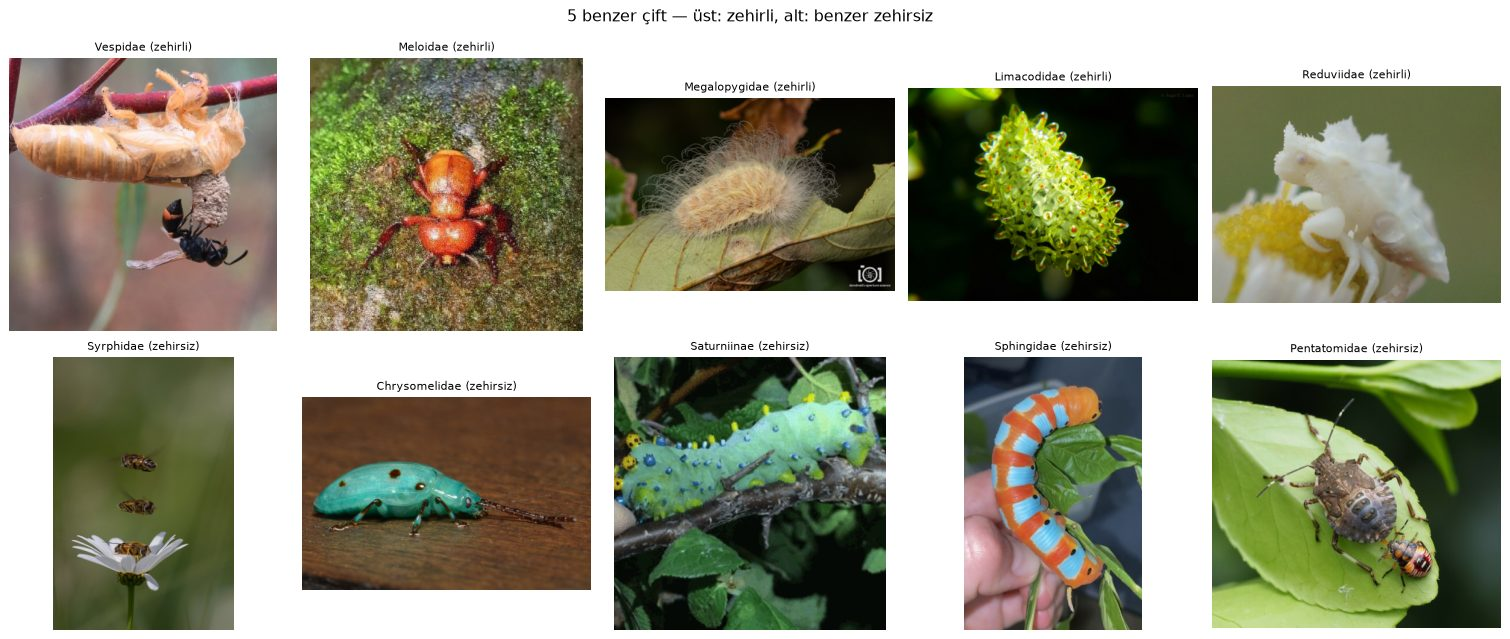

In [3]:
# Üst sıra zehirli, alt sıra ona benzeyen zehirsiz böcek
sira = [z for z, _, _ in CIFTLER] + [zs for _, zs, _ in CIFTLER]
goster([foto(g, 0) for g in sira], [etiket(g) for g in sira], sutun=5, boyut=3.4,
       baslik="5 benzer çift — üst: zehirli, alt: benzer zehirsiz")

## 3. Görüntünün Sayısal Temsili

Dijital bir renkli görüntü, **yükseklik × genişlik × 3** boyutunda bir sayı matrisidir. Her piksel; kırmızı (R), yeşil (G) ve mavi (B) kanallarında 0 ile 255 arasında birer tamsayı değeri taşır (8 bit, `uint8`). 0 değeri ışığın hiç olmadığını (siyah), 255 değeri ise tam parlaklığı ifade eder.

Aşağıda bir eyer sırtlı tırtıl fotoğrafının ortasına adım adım yaklaşılmıştır: önce pikseller tek tek görünür hale gelmekte, ardından 12×12 piksellik bir bölgenin gri ton değerleri sayı olarak gösterilmektedir.

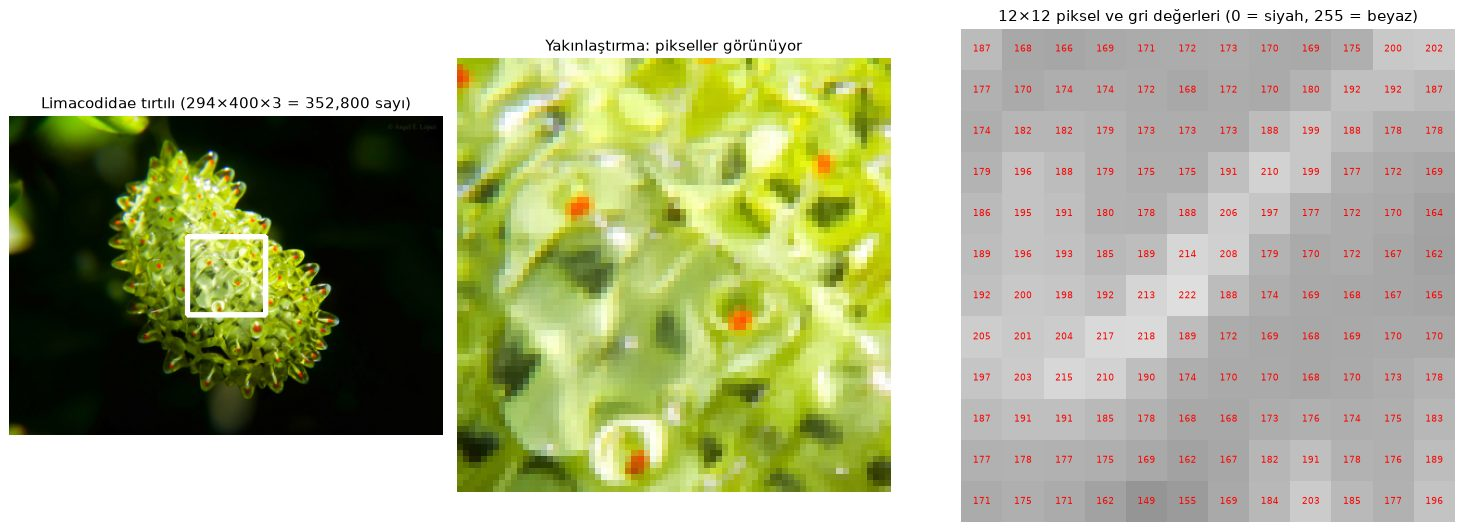

Boyut (yükseklik, genişlik, kanal): (294, 400, 3) | veri tipi: uint8
Ortadaki pikselin (R, G, B) değeri: [189 204 100]


In [4]:
f = foto("Limacodidae", 0)
gri = cv2.cvtColor(f, cv2.COLOR_RGB2GRAY)
h, w = gri.shape
y0, x0 = h // 2 - 6, w // 2 - 6
parca = gri[y0:y0 + 12, x0:x0 + 12]

fig, axes = plt.subplots(1, 3, figsize=(17, 6), gridspec_kw={"width_ratios": [1, 1, 1.4]})
cerceve = f.copy()
cv2.rectangle(cerceve, (x0 - 30, y0 - 30), (x0 + 42, y0 + 42), (255, 255, 255), 3)
axes[0].imshow(cerceve); axes[0].set_title(f"Limacodidae tırtılı ({h}×{w}×3 = {h * w * 3:,} sayı)")
axes[1].imshow(f[y0 - 30:y0 + 42, x0 - 30:x0 + 42], interpolation="nearest"); axes[1].set_title("Yakınlaştırma: pikseller görünüyor")
axes[2].imshow(parca, cmap="gray", vmin=0, vmax=255, interpolation="nearest")
for i in range(12):
    for j in range(12):
        axes[2].text(j, i, parca[i, j], ha="center", va="center", fontsize=7, color="red" if parca[i, j] > 127 else "yellow")
axes[2].set_title("12×12 piksel ve gri değerleri (0 = siyah, 255 = beyaz)")
for a in axes:
    a.axis("off")
plt.tight_layout(); plt.show()
print("Boyut (yükseklik, genişlik, kanal):", f.shape, "| veri tipi:", f.dtype)
print("Ortadaki pikselin (R, G, B) değeri:", f[h // 2, w // 2])

## 4. RGB Renk Kanalları

Renkli görüntü üç kanala ayrılmış ve her kanal gri tonlu bir görüntü olarak gösterilmiştir. Bir kanalda parlak görünen bölgeler, o renk bileşeninin yoğun olduğu bölgelerdir.

Örneğin sarı renk, kırmızı ve yeşil bileşenlerin birleşiminden oluştuğu için sarı bölgeler R ve G kanallarında parlak, B kanalında koyu görünür. Yeşil yapraklar ise yalnızca G kanalında parlaktır. Her satırda farklı bir böcek ve onun üç renk kanalı yer almaktadır.

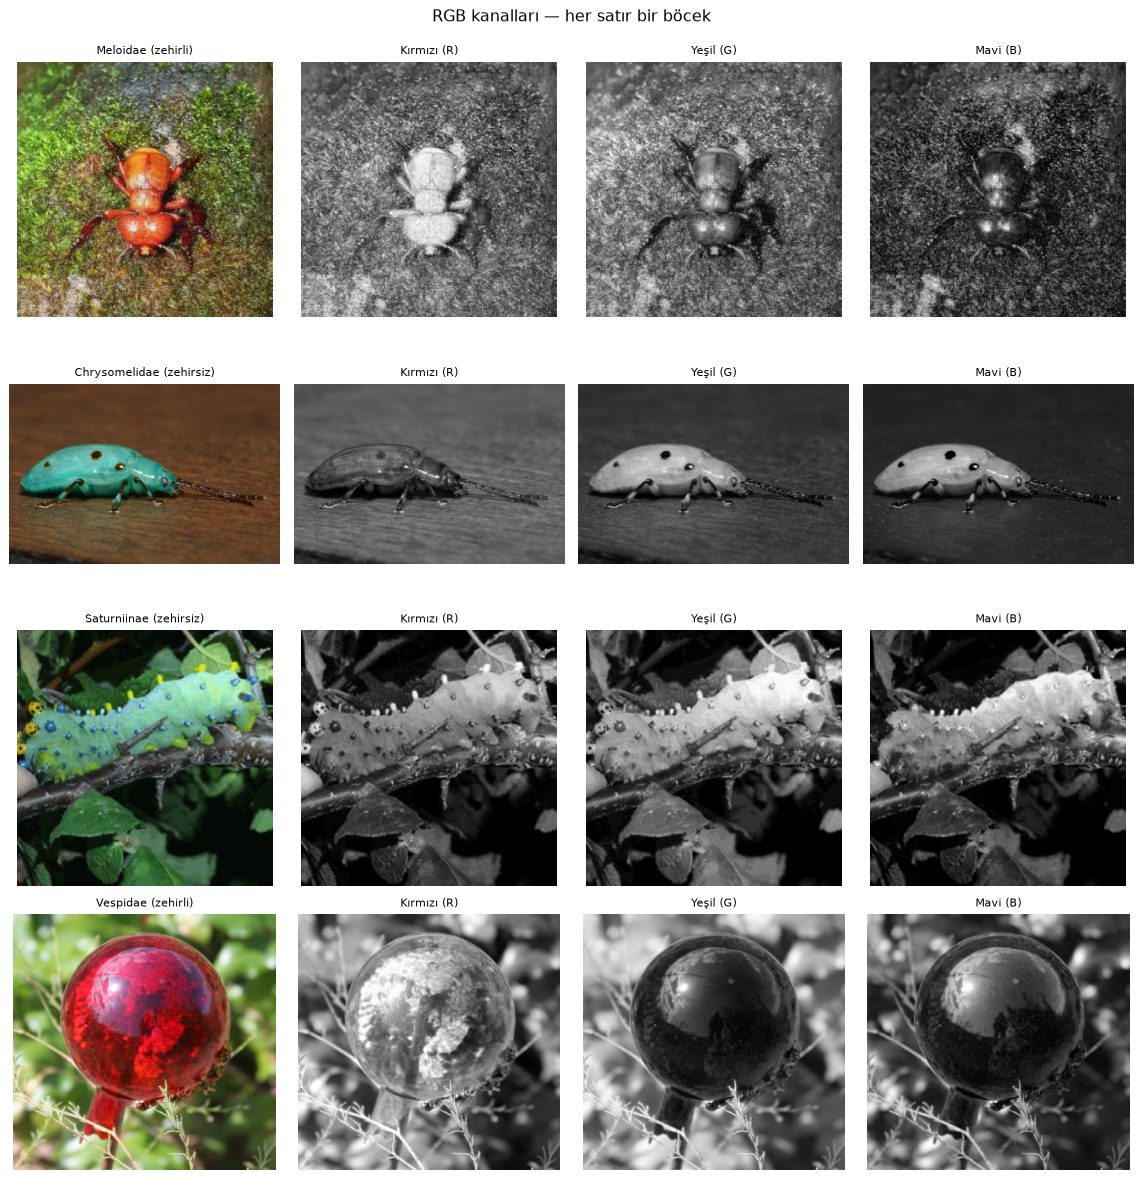

In [5]:
secim = [("Meloidae", 0), ("Chrysomelidae", 0), ("Saturniinae", 0), ("Vespidae", 1)]
resimler, basliklar = [], []
for g, i in secim:
    r = foto(g, i)
    resimler += [r, r[:, :, 0], r[:, :, 1], r[:, :, 2]]
    basliklar += [etiket(g), "Kırmızı (R)", "Yeşil (G)", "Mavi (B)"]
goster(resimler, basliklar, sutun=4, boyut=3.2, baslik="RGB kanalları — her satır bir böcek")

## 5. Gri Tonlama ve Histogram

Renkli görüntü, insan gözünün renklere farklı duyarlılığını hesaba katan ağırlıklı bir ortalama ile gri tonlu görüntüye dönüştürülür:

$$Gri = 0{,}299 \cdot R + 0{,}587 \cdot G + 0{,}114 \cdot B$$

**Histogram**, görüntüde her parlaklık değerinden (0–255) kaç piksel bulunduğunu gösteren grafiktir. Histogramın sola yığılması karanlık, sağa yığılması aydınlık bir görüntüye işaret eder; değerlerin dar bir aralıkta toplanması ise kontrastın düşük olduğunu gösterir.

On grubun birer fotoğrafı için gri tonlu görüntü ve altında histogramlar verilmiştir. Siyah çizgi gri tonun, renkli çizgiler R, G ve B kanallarının histogramıdır. Başlıklarda ortalama parlaklık ve kontrast ölçüsü olarak standart sapma yer almaktadır.

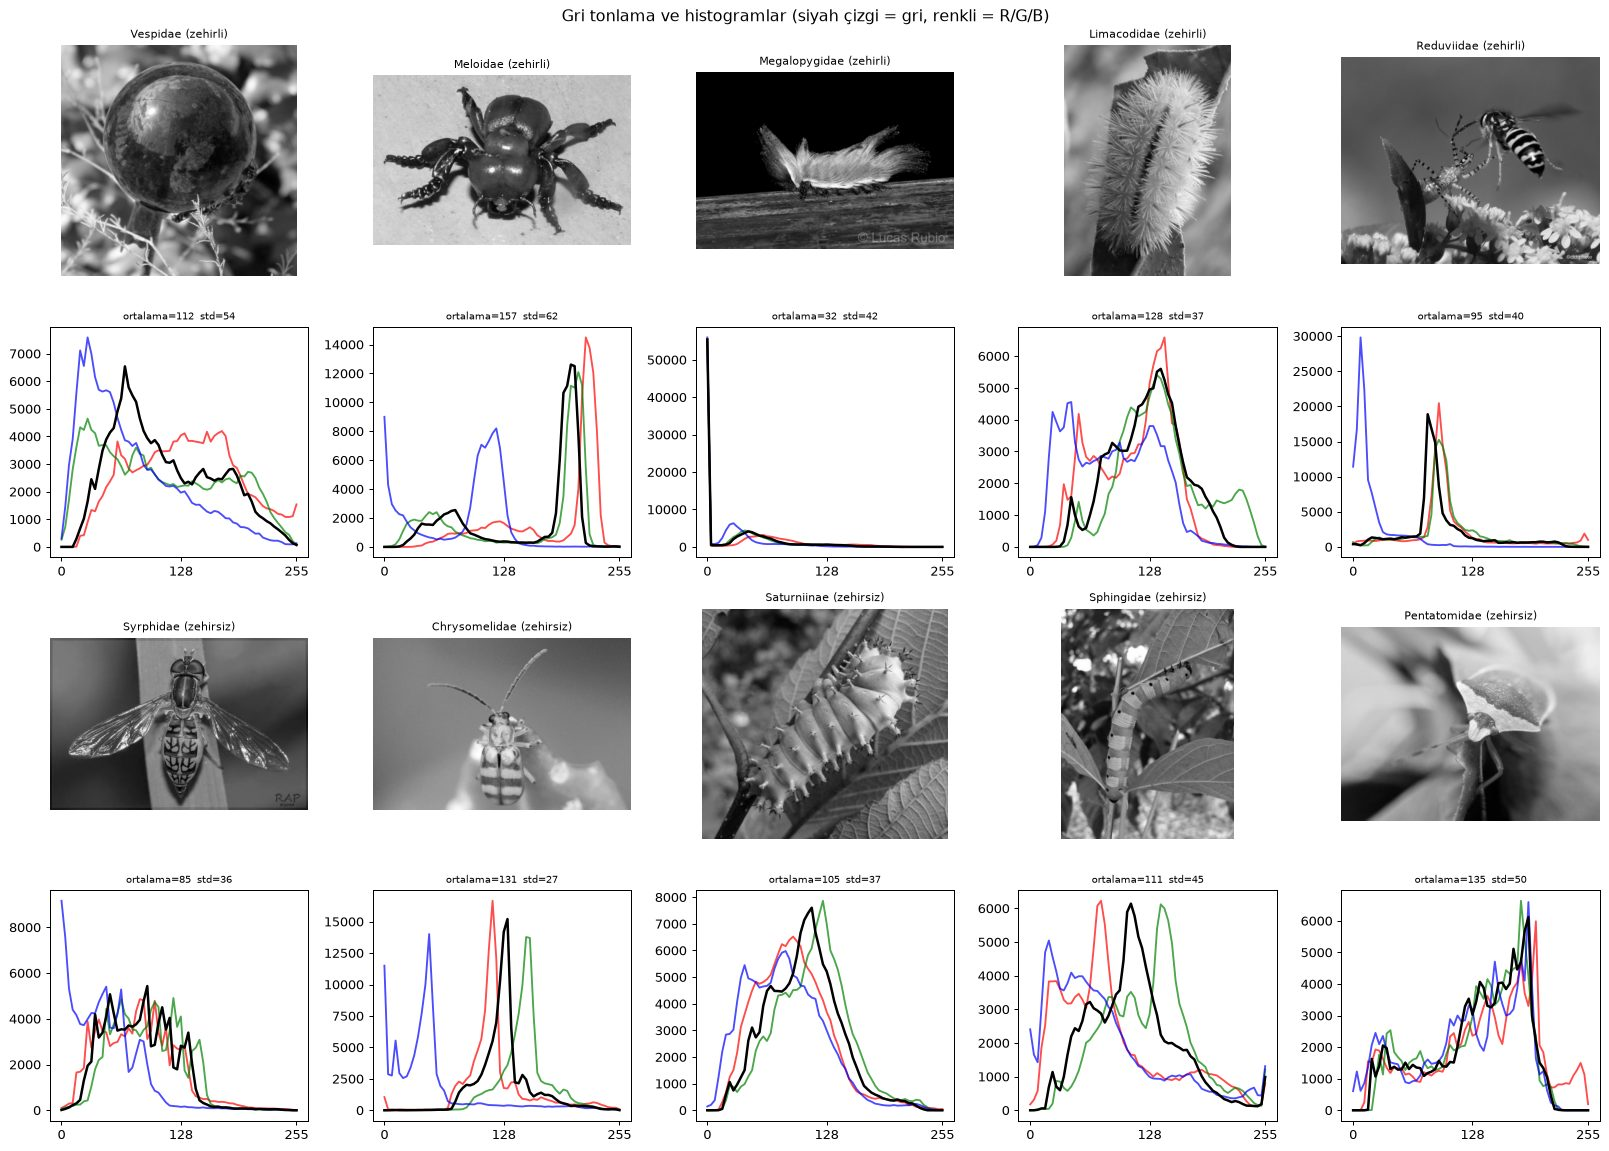

In [6]:
fig, axes = plt.subplots(4, 5, figsize=(18, 13))
for k, g in enumerate(sira):
    r = foto(g, 1)
    gr = cv2.cvtColor(r, cv2.COLOR_RGB2GRAY)
    a1, a2 = axes[(k // 5) * 2, k % 5], axes[(k // 5) * 2 + 1, k % 5]
    a1.imshow(gr, cmap="gray"); a1.set_title(etiket(g), fontsize=9); a1.axis("off")
    for i, renk in enumerate(["red", "green", "blue"]):
        a2.plot(cv2.calcHist([r], [i], None, [64], [0, 256]), color=renk, alpha=0.7)
    a2.plot(cv2.calcHist([gr], [0], None, [64], [0, 256]), color="black", lw=2)
    a2.set_title(f"ortalama={gr.mean():.0f}  std={gr.std():.0f}", fontsize=8)
    a2.set_xticks([0, 32, 63]); a2.set_xticklabels([0, 128, 255])
plt.suptitle("Gri tonlama ve histogramlar (siyah çizgi = gri, renkli = R/G/B)", fontsize=13)
plt.tight_layout(); plt.show()

## 6. Histogram Eşitleme ve CLAHE

Karanlık veya düşük kontrastlı görüntülerde piksel değerleri dar bir aralıkta toplandığı için ayrıntılar seçilemez. Bu sorunu gidermek için iki yöntem uygulanmıştır:

- **Histogram eşitleme:** Piksel değerlerini birikimli dağılım fonksiyonu yardımıyla 0–255 aralığının tamamına yayar. İşlem tüm görüntüye aynı şekilde uygulanır.
- **CLAHE (Contrast Limited Adaptive Histogram Equalization):** Görüntüyü 8×8 bloğa böler ve eşitlemeyi her blokta ayrı yapar. Kontrast artışını sınırladığı için gürültünün aşırı büyümesini önler.

İlk olarak veri setindeki **en karanlık fotoğraf** otomatik olarak belirlenmiş ve iki yöntemle iyileştirilmiştir. Renkli görüntülerde CLAHE, renkleri bozmamak için yalnızca LAB renk uzayının parlaklık (L) kanalına uygulanmıştır. İkinci olarak beş fotoğraf yapay olarak karartılmış ve CLAHE ile yeniden görünür hale getirilmiştir.

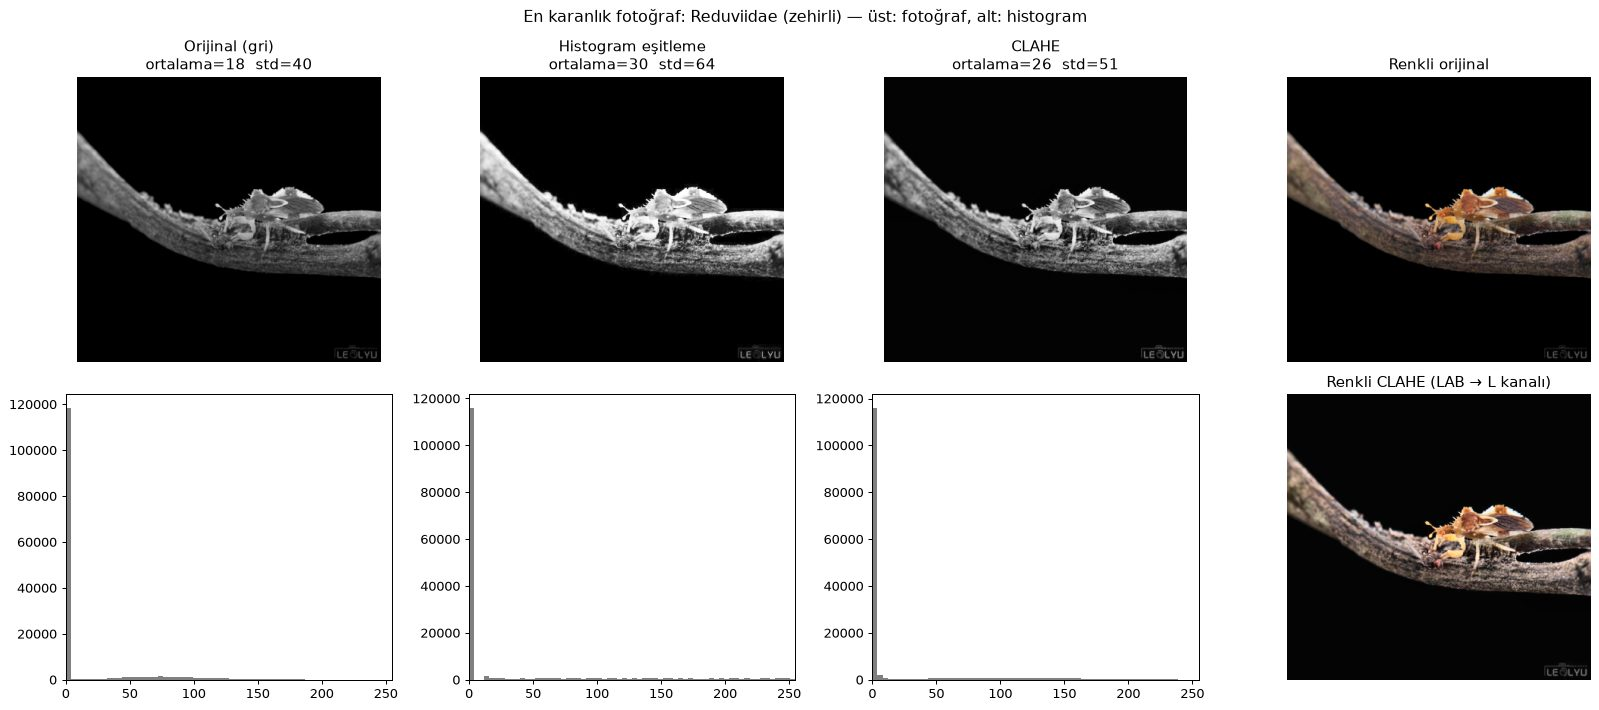

In [7]:
clahe_op = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))

def renkli_clahe(rgb):
    lab = cv2.cvtColor(rgb, cv2.COLOR_RGB2LAB)
    lab[:, :, 0] = clahe_op.apply(lab[:, :, 0])
    return cv2.cvtColor(lab, cv2.COLOR_LAB2RGB)

parlaklik = df.resim.apply(lambda r: cv2.cvtColor(r, cv2.COLOR_RGB2GRAY).mean())
en_karanlik = df.loc[parlaklik.idxmin()]
kr = en_karanlik.resim
kg = cv2.cvtColor(kr, cv2.COLOR_RGB2GRAY)
esit, clahe = cv2.equalizeHist(kg), clahe_op.apply(kg)

fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for j, (r, b) in enumerate([(kg, "Orijinal (gri)"), (esit, "Histogram eşitleme"), (clahe, "CLAHE")]):
    axes[0, j].imshow(r, cmap="gray", vmin=0, vmax=255); axes[0, j].set_title(f"{b}\nortalama={r.mean():.0f}  std={r.std():.0f}")
    axes[1, j].hist(r.ravel(), bins=64, range=(0, 255), color="gray"); axes[1, j].set_xlim(0, 255)
axes[0, 3].imshow(kr); axes[0, 3].set_title("Renkli orijinal")
axes[1, 3].imshow(renkli_clahe(kr)); axes[1, 3].set_title("Renkli CLAHE (LAB → L kanalı)")
for a in axes[0]:
    a.axis("off")
axes[1, 3].axis("off")
plt.suptitle(f"En karanlık fotoğraf: {etiket(en_karanlik.grup)} — üst: fotoğraf, alt: histogram", fontsize=13)
plt.tight_layout(); plt.show()

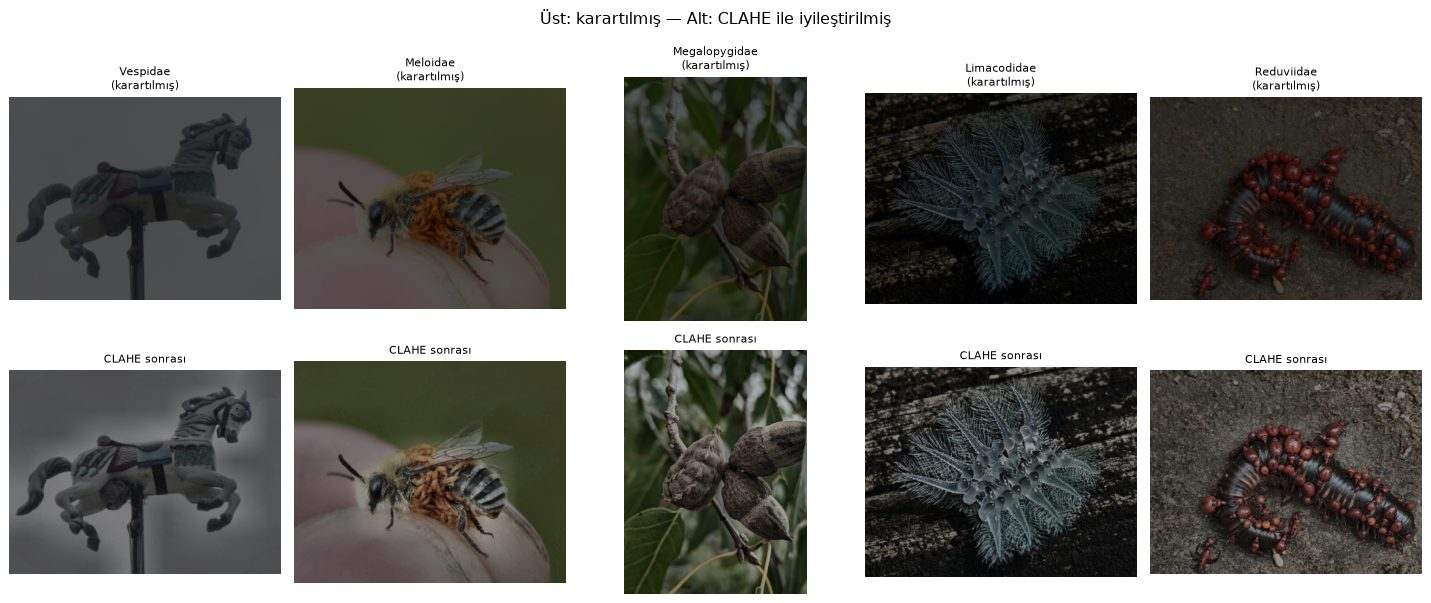

In [8]:
# Yapay olarak karartılmış 5 fotoğraf ve CLAHE ile kurtarılmış halleri
resimler, basliklar = [], []
for g in [z for z, _, _ in CIFTLER]:
    r = (foto(g, 2) * 0.35).astype(np.uint8)
    resimler += [r]; basliklar += [f"{g}\n(karartılmış)"]
for g in [z for z, _, _ in CIFTLER]:
    resimler += [renkli_clahe((foto(g, 2) * 0.35).astype(np.uint8))]; basliklar += ["CLAHE sonrası"]
goster(resimler, basliklar, sutun=5, boyut=3.2, baslik="Üst: karartılmış — Alt: CLAHE ile iyileştirilmiş")

## 7. Gürültü Giderme Filtreleri

Görüntüye iki farklı yapay gürültü eklenmiştir:

- **Gauss gürültüsü:** Her piksele ortalaması 0, standart sapması 25 olan rastgele bir sapma eklenir (karıncalanma görünümü).
- **Tuz-biber gürültüsü:** Piksellerin %6'sı rastgele olarak tamamen siyah veya beyaz yapılır.

Ardından aşağıdaki filtreler uygulanmış ve başarıları **PSNR** (Peak Signal-to-Noise Ratio, tepe sinyal-gürültü oranı, dB) ile ölçülmüştür. PSNR değeri ne kadar yüksekse, filtrelenmiş görüntü orijinal görüntüye o kadar yakındır.

| Filtre | Çalışma prensibi |
|---|---|
| Ortalama (5×5) | Penceredeki piksellerin aritmetik ortalaması |
| Gauss (5×5) | Merkeze yakın piksellere daha fazla ağırlık veren ağırlıklı ortalama |
| Medyan (3×3 ve 5×5) | Penceredeki değerlerin ortancası; aykırı değerlerden etkilenmez |
| Bilateral | Hem uzaklığa hem renk benzerliğine göre ağırlık verir; kenarları korur |

Görsellerin alt sırasında, farkların daha iyi görülebilmesi için görüntünün orta bölgesi yakınlaştırılmıştır.

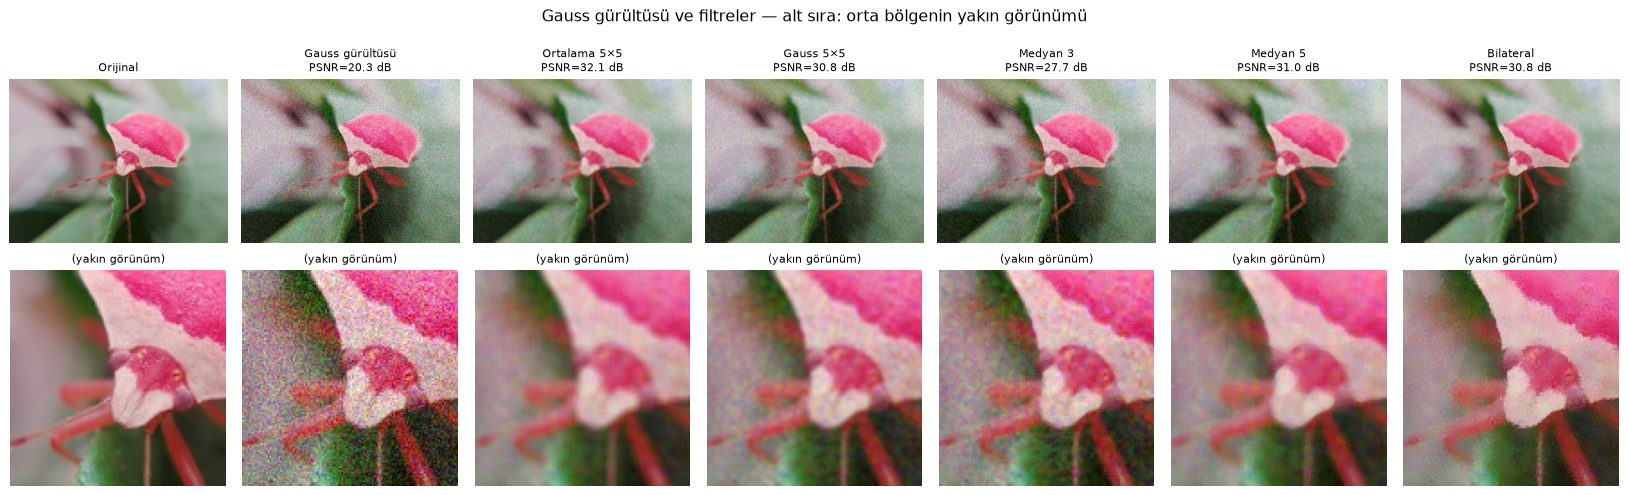

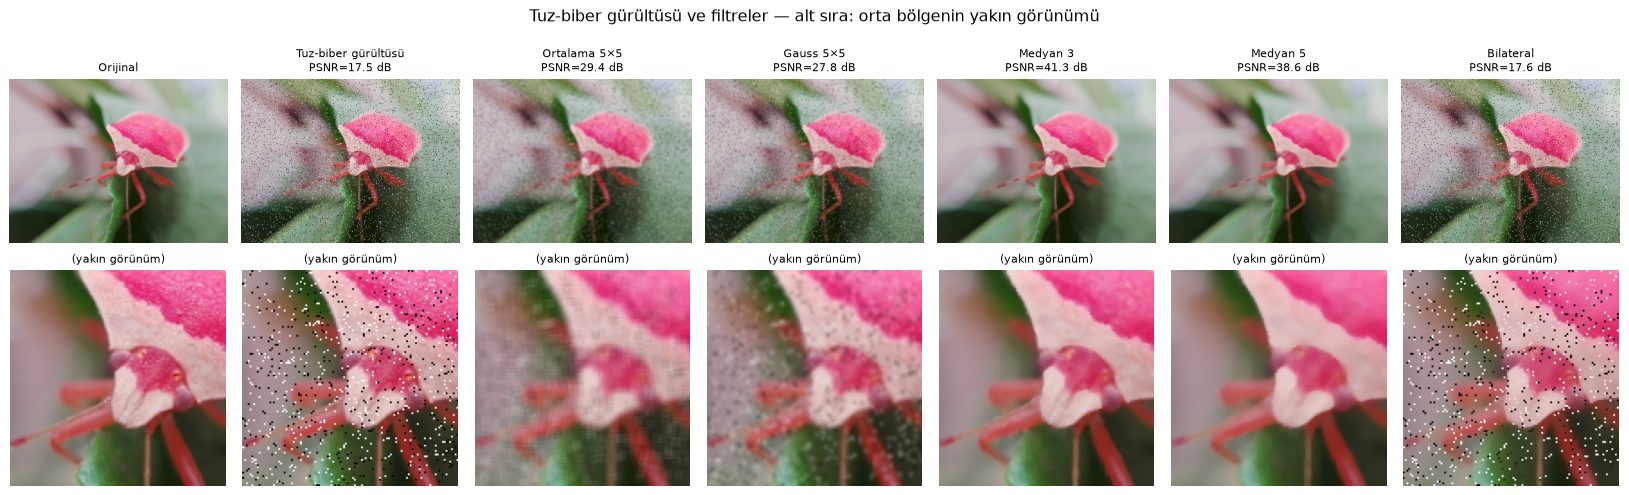

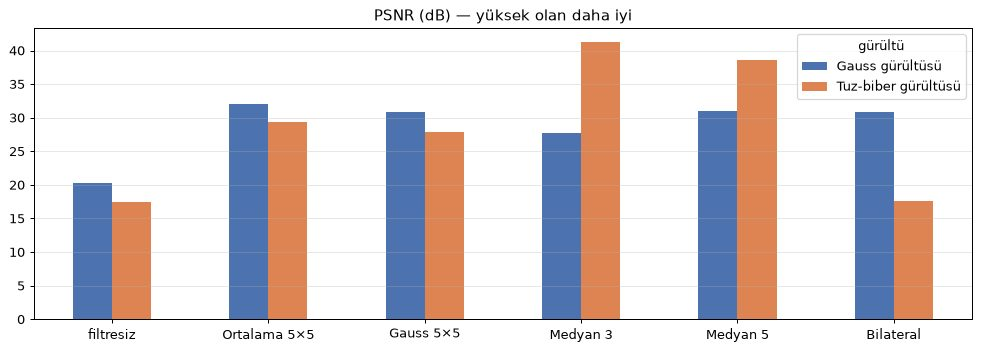

,filtresiz,Ortalama 5×5,Gauss 5×5,Medyan 3,Medyan 5,Bilateral
gürültü,,,,,,
Gauss gürültüsü,20.33,32.09,30.85,27.69,31.04,30.78
Tuz-biber gürültüsü,17.45,29.37,27.81,41.30,38.56,17.57


In [9]:
f = foto("Pentatomidae", 1)
gauss_gurultu = np.clip(f + np.random.normal(0, 25, f.shape), 0, 255).astype(np.uint8)
tuz_biber = f.copy()
m = np.random.rand(*f.shape[:2])
tuz_biber[m < 0.03] = 0
tuz_biber[m > 0.97] = 255

def filtrele(x):
    return {"Ortalama 5×5": cv2.blur(x, (5, 5)), "Gauss 5×5": cv2.GaussianBlur(x, (5, 5), 0),
            "Medyan 3": cv2.medianBlur(x, 3), "Medyan 5": cv2.medianBlur(x, 5),
            "Bilateral": cv2.bilateralFilter(x, 9, 75, 75)}

yy, xx = f.shape[0] // 2 - 60, f.shape[1] // 2 - 60
satir = []
for g_ad, g in [("Gauss gürültüsü", gauss_gurultu), ("Tuz-biber gürültüsü", tuz_biber)]:
    sonuc = filtrele(g)
    hepsi = [("Orijinal", f), (g_ad, g)] + list(sonuc.items())
    goster([v for _, v in hepsi] + [v[yy:yy + 120, xx:xx + 120] for _, v in hepsi],
           [k if k == "Orijinal" else f"{k}\nPSNR={cv2.PSNR(f, v):.1f} dB" for k, v in hepsi] + ["(yakın görünüm)"] * len(hepsi),
           sutun=7, boyut=2.6, baslik=f"{g_ad} ve filtreler — alt sıra: orta bölgenin yakın görünümü")
    satir.append({"gürültü": g_ad, "filtresiz": cv2.PSNR(f, g), **{k: cv2.PSNR(f, v) for k, v in sonuc.items()}})

psnr_df = pd.DataFrame(satir).set_index("gürültü").round(2)
psnr_df.T.plot.bar(figsize=(11, 4), rot=0, title="PSNR (dB) — yüksek olan daha iyi", color=["#4c72b0", "#dd8452"])
plt.grid(alpha=0.3, axis="y"); plt.tight_layout(); plt.show()
psnr_df

## 8. Evrişim ve Kenar Bulma

**Evrişim (konvolüsyon)**, küçük bir sayı matrisinin (çekirdek veya filtre) görüntü üzerinde kaydırılması ve her konumda altındaki piksellerle çarpılıp toplanması işlemidir. Çekirdeğin değerleri değiştirildiğinde aynı işlem bulanıklaştırma, keskinleştirme veya kenar bulma gibi tamamen farklı sonuçlar üretir.

İlk görselde yedi farklı 3×3 çekirdek ve bu çekirdeklerin dokusu belirgin bir kedi tırtılı fotoğrafına uygulanmış hali gösterilmiştir. Evrişim, evrişimli sinir ağlarının (CNN) da temel işlemidir. Burada çekirdek değerleri elle tanımlanmışken, CNN'ler bu değerleri eğitim sırasında veriden kendileri öğrenir.

Ardından üç kenar bulma yöntemi karşılaştırılmıştır:

- **Sobel:** Yatay ve dikey yöndeki parlaklık değişimini (birinci türev) hesaplar; iki yönün birleşimi gradyan büyüklüğünü verir.
- **Laplace:** Tüm yönlerdeki ani parlaklık değişimini (ikinci türev) hesaplar.
- **Canny:** Gauss ile yumuşatma, gradyan hesaplama, kenarları inceltme ve çift eşikleme adımlarından oluşur; ince ve sürekli kenarlar üretir.

Elle tanımlanan Sobel çekirdeğinin sonucu, OpenCV'nin hazır `cv2.Sobel` fonksiyonuyla karşılaştırılarak doğrulanmıştır. Son görselde Canny yöntemi on grubun birer fotoğrafına uygulanmıştır.

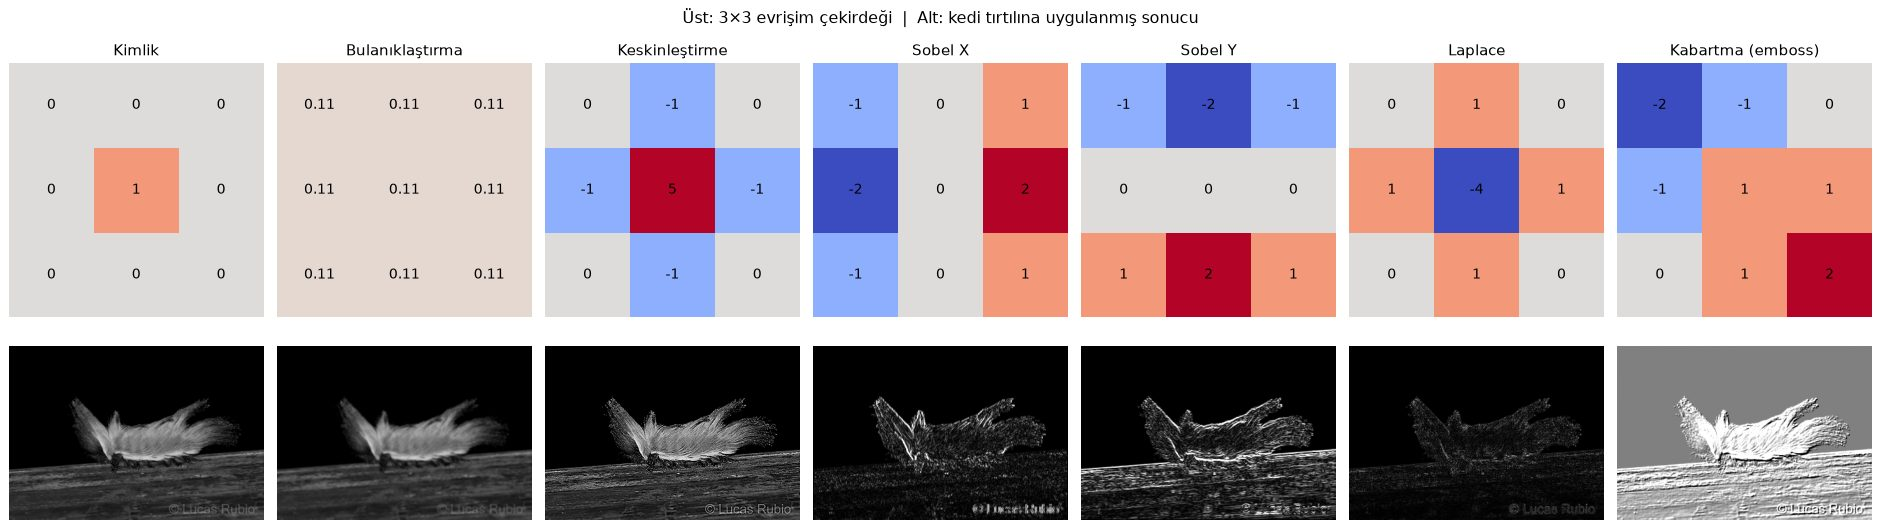

In [10]:
f = foto("Megalopygidae", 1)
gri = cv2.cvtColor(f, cv2.COLOR_RGB2GRAY)
CEKIRDEKLER = {
    "Kimlik":            np.array([[0, 0, 0], [0, 1, 0], [0, 0, 0]]),
    "Bulanıklaştırma":   np.ones((3, 3)) / 9,
    "Keskinleştirme":    np.array([[0, -1, 0], [-1, 5, -1], [0, -1, 0]]),
    "Sobel X":           np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]]),
    "Sobel Y":           np.array([[-1, -2, -1], [0, 0, 0], [1, 2, 1]]),
    "Laplace":           np.array([[0, 1, 0], [1, -4, 1], [0, 1, 0]]),
    "Kabartma (emboss)": np.array([[-2, -1, 0], [-1, 1, 1], [0, 1, 2]]),
}
fig, axes = plt.subplots(2, len(CEKIRDEKLER), figsize=(3 * len(CEKIRDEKLER), 6.6))
for j, (ad, c) in enumerate(CEKIRDEKLER.items()):
    c = c.astype(np.float32)
    axes[0, j].imshow(c, cmap="coolwarm", vmin=-2, vmax=2)
    for (i, k), v in np.ndenumerate(c):
        axes[0, j].text(k, i, f"{v:.2g}", ha="center", va="center", fontsize=11)
    axes[0, j].set_title(ad); axes[0, j].axis("off")
    sonuc = cv2.filter2D(gri.astype(np.float32), -1, c)
    if ad in ("Sobel X", "Sobel Y", "Laplace"):
        sonuc = np.abs(sonuc)
    elif ad == "Kabartma (emboss)":
        sonuc = sonuc + 128
    axes[1, j].imshow(np.clip(sonuc, 0, 255), cmap="gray", vmin=0, vmax=255); axes[1, j].axis("off")
plt.suptitle("Üst: 3×3 evrişim çekirdeği  |  Alt: kedi tırtılına uygulanmış sonucu", fontsize=13)
plt.tight_layout(); plt.show()

Elle yazılan Sobel çekirdeği ile cv2.Sobel aynı sonucu veriyor mu? True


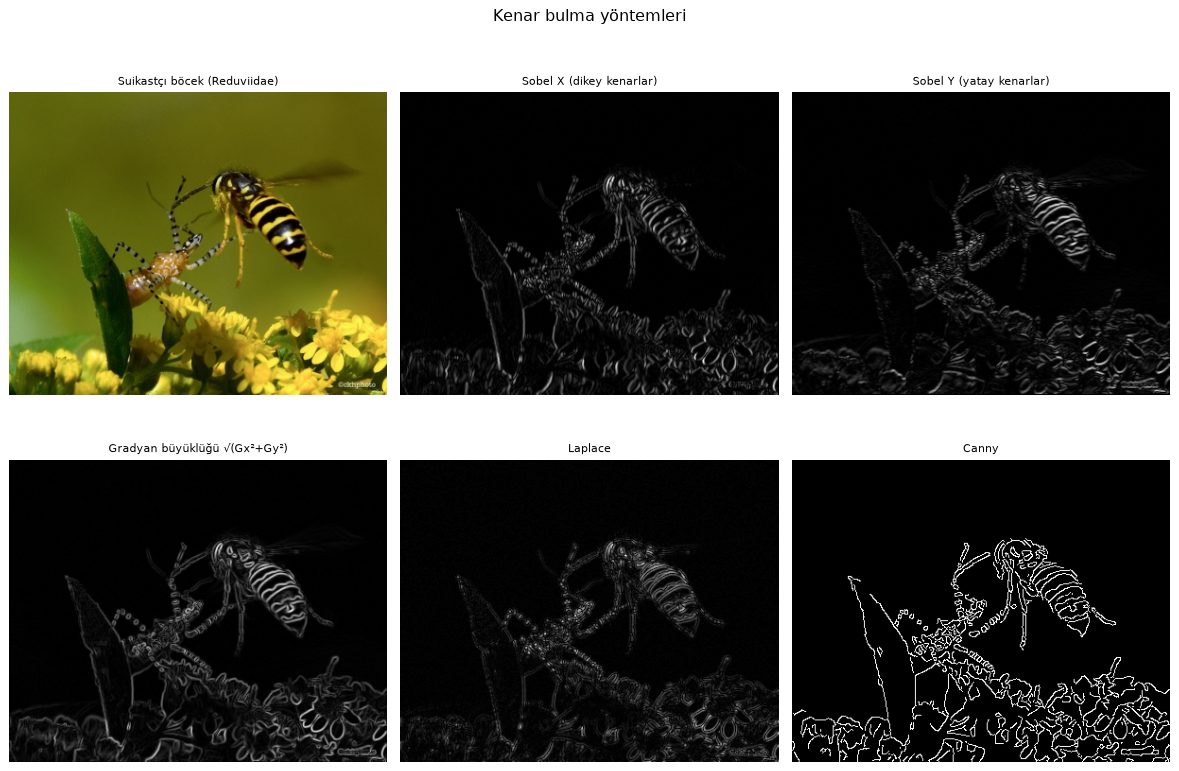

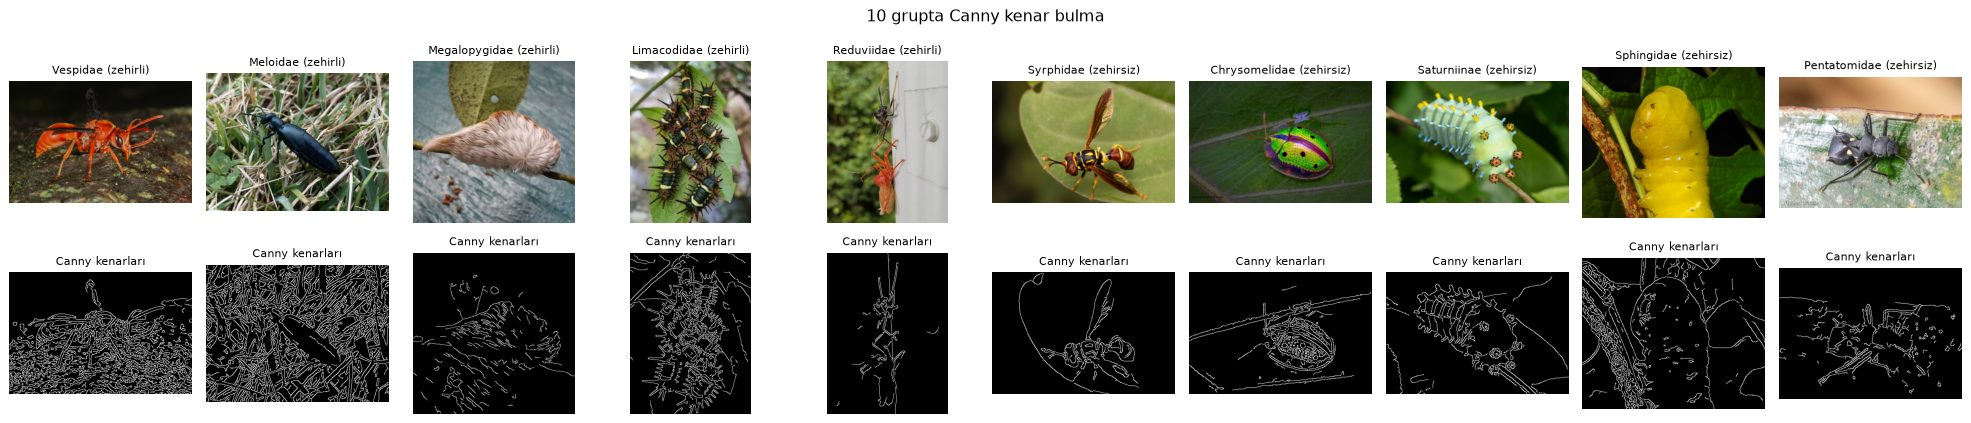

In [11]:
def canny(g):
    med = np.median(g)
    return cv2.Canny(cv2.GaussianBlur(g, (5, 5), 0), int(max(0, 0.66 * med)), int(min(255, 1.33 * med)))

f = foto("Reduviidae", 1)
gri = cv2.cvtColor(f, cv2.COLOR_RGB2GRAY)
gx = cv2.Sobel(gri, cv2.CV_32F, 1, 0, ksize=3)
gy = cv2.Sobel(gri, cv2.CV_32F, 0, 1, ksize=3)
elle = cv2.filter2D(gri.astype(np.float32), -1, CEKIRDEKLER["Sobel X"].astype(np.float32))
print("Elle yazılan Sobel çekirdeği ile cv2.Sobel aynı sonucu veriyor mu?", np.allclose(elle, gx, atol=1e-3))

goster([f, np.abs(gx), np.abs(gy), cv2.magnitude(gx, gy),
        np.abs(cv2.Laplacian(cv2.GaussianBlur(gri, (3, 3), 0), cv2.CV_32F)), canny(gri)],
       ["Suikastçı böcek (Reduviidae)", "Sobel X (dikey kenarlar)", "Sobel Y (yatay kenarlar)",
        "Gradyan büyüklüğü √(Gx²+Gy²)", "Laplace", "Canny"], sutun=3, boyut=4.4, baslik="Kenar bulma yöntemleri")

goster([foto(g, 3) for g in sira] + [canny(cv2.cvtColor(foto(g, 3), cv2.COLOR_RGB2GRAY)) for g in sira],
       [etiket(g) for g in sira] + ["Canny kenarları"] * len(sira), sutun=10, boyut=2.2,
       baslik="10 grupta Canny kenar bulma")

## 9. HSV Renk Uzayı ve Uyarı Rengi Maskesi

RGB uzayında bir renk üç kanala dağıldığı için belirli bir rengi seçmek zordur. **HSV** uzayı rengi üç anlamlı bileşene ayırır: **H** (renk tonu; OpenCV'de 0–179), **S** (doygunluk) ve **V** (parlaklık). Böylece bir renk, tek bir renk tonu aralığıyla seçilebilir.

Zehirli böceklerin birçoğu avcılarını uyarmak için sarı, turuncu, kırmızı ve siyah gibi dikkat çekici renkler taşır. Bu olaya **aposematizm** denir. Uyarı renkleri aşağıdaki eşik değerleriyle maskelenmiştir:

| Renk | H (renk tonu) | S (doygunluk) | V (parlaklık) |
|---|---|---|---|
| Sarı / turuncu | 10–35 | > 100 | > 100 |
| Kırmızı | 0–10 veya 165–179 | > 100 | > 80 |
| Siyah | tümü | tümü | < 60 |

Önce renk tonu ekseni gösterilmiş, ardından uyarı rengi oranı en yüksek olan fotoğraf otomatik olarak seçilerek H, S, V kanalları ve renk maskeleri çıkarılmıştır. Son olarak maske on grubun birer fotoğrafına uygulanmıştır.

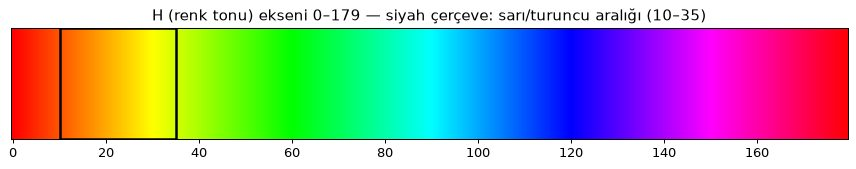

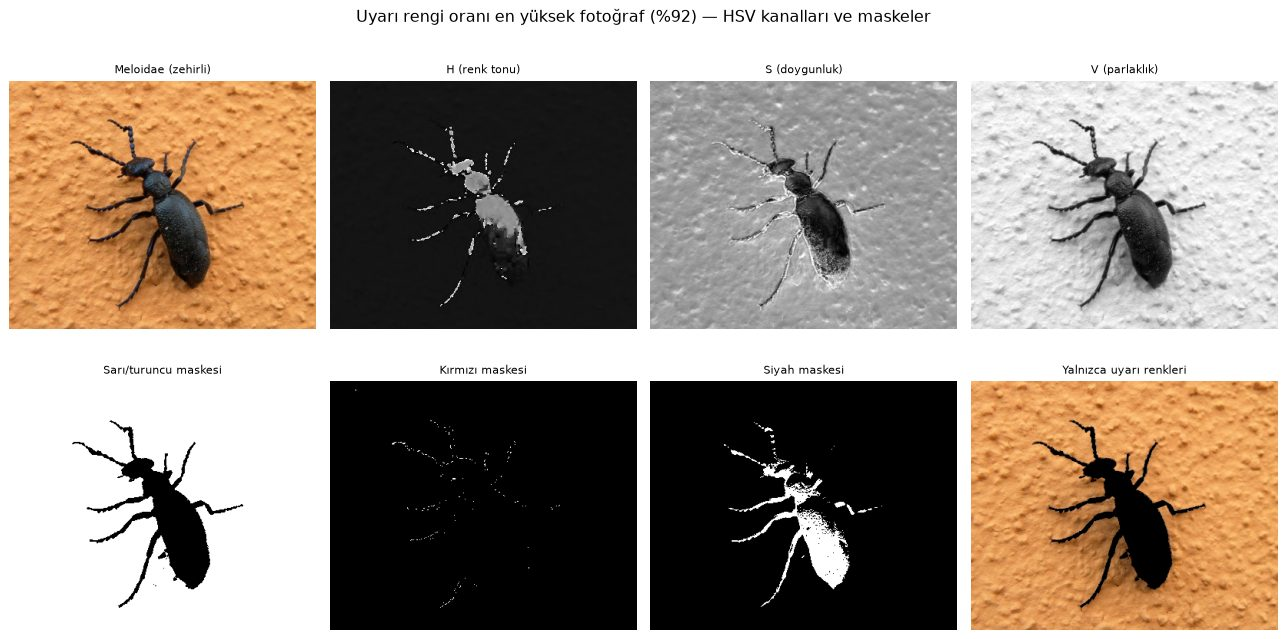

Dikkat: renk maskesi yalnızca rengi seçer, nesneyi tanımaz. Bu fotoğraftaki sarı-turuncu pikseller böcekten değil,
arka plandan geliyor olabilir. Bu nedenle 12. bölümdeki ölçümler, böcek GrabCut ile arka plandan ayrıldıktan sonra yapılmıştır.


In [12]:
def renk_maskeleri(rgb):
    hsv = cv2.cvtColor(rgb, cv2.COLOR_RGB2HSV)
    sari = cv2.inRange(hsv, (10, 100, 100), (35, 255, 255))
    kirmizi = cv2.inRange(hsv, (0, 100, 80), (10, 255, 255)) | cv2.inRange(hsv, (165, 100, 80), (179, 255, 255))
    siyah = cv2.inRange(hsv, (0, 0, 0), (179, 255, 60))
    return hsv, sari, kirmizi, siyah

ton = np.zeros((40, 180, 3), np.uint8); ton[:, :, 0] = np.arange(180); ton[:, :, 1:] = 255
plt.figure(figsize=(12, 1.6)); plt.imshow(cv2.cvtColor(ton, cv2.COLOR_HSV2RGB), aspect="auto")
plt.axvspan(10, 35, color="none", ec="black", lw=2)
plt.title("H (renk tonu) ekseni 0–179 — siyah çerçeve: sarı/turuncu aralığı (10–35)"); plt.yticks([]); plt.show()

# 250 fotoğraf arasından uyarı rengi en yüksek olanı otomatik seç
oran = df.resim.apply(lambda r: ((renk_maskeleri(r)[1] | renk_maskeleri(r)[2]) > 0).mean())
en_renkli = df.loc[oran.idxmax()]
f = en_renkli.resim
hsv, sari, kirmizi, siyah = renk_maskeleri(f)
goster([f, hsv[:, :, 0], hsv[:, :, 1], hsv[:, :, 2], sari, kirmizi, siyah, cv2.bitwise_and(f, f, mask=sari | kirmizi)],
       [etiket(en_renkli.grup), "H (renk tonu)", "S (doygunluk)", "V (parlaklık)",
        "Sarı/turuncu maskesi", "Kırmızı maskesi", "Siyah maskesi", "Yalnızca uyarı renkleri"],
       sutun=4, boyut=3.6, baslik=f"Uyarı rengi oranı en yüksek fotoğraf (%{100 * oran.max():.0f}) — HSV kanalları ve maskeler")
print("Dikkat: renk maskesi yalnızca rengi seçer, nesneyi tanımaz. Bu fotoğraftaki sarı-turuncu pikseller böcekten değil,")
print("arka plandan geliyor olabilir. Bu yüzden 12. bölümde ölçümler önce böcek arka plandan ayrılarak (GrabCut) yapılır.")

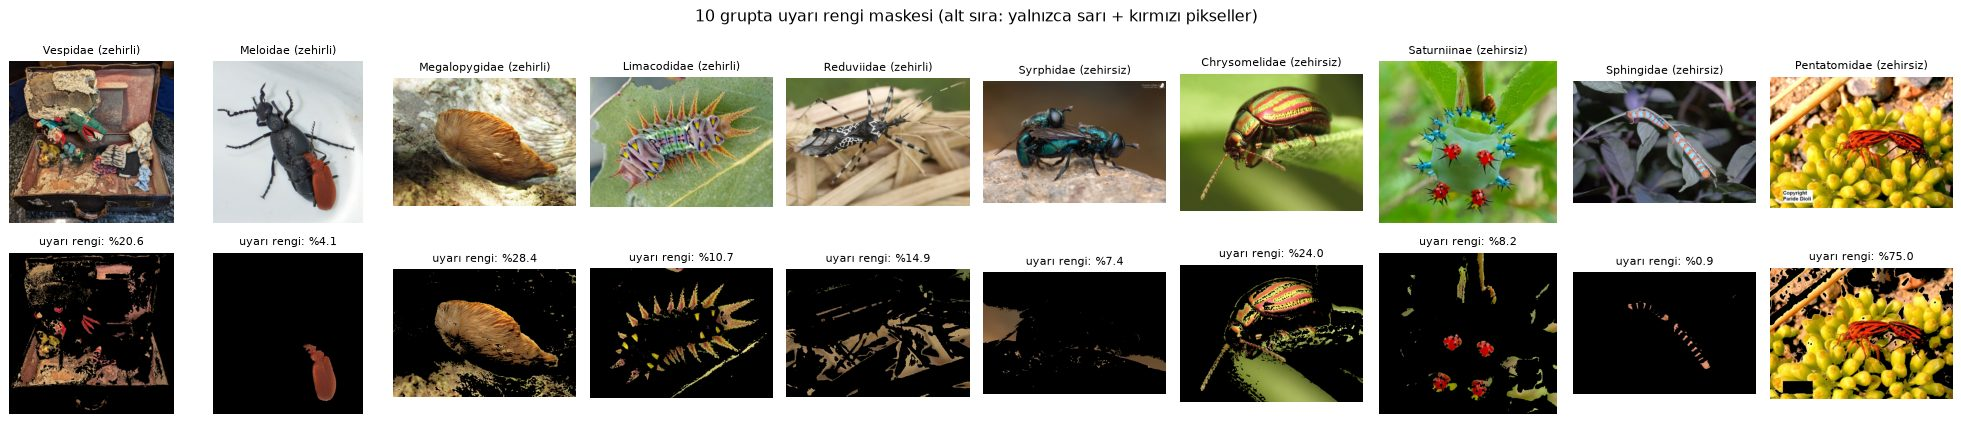

In [13]:
resimler, basliklar = [], []
for g in sira:
    r = foto(g, 4)
    _, s, k, _ = renk_maskeleri(r)
    resimler.append(r); basliklar.append(etiket(g))
for g in sira:
    r = foto(g, 4)
    _, s, k, _ = renk_maskeleri(r)
    resimler.append(cv2.bitwise_and(r, r, mask=s | k)); basliklar.append(f"uyarı rengi: %{100 * ((s | k) > 0).mean():.1f}")
goster(resimler, basliklar, sutun=10, boyut=2.2, baslik="10 grupta uyarı rengi maskesi (alt sıra: yalnızca sarı + kırmızı pikseller)")

## 10. Morfolojik İşlemler

Renk maskeleri genellikle küçük gürültü noktaları ve delikler içerir. Morfolojik işlemler, ikili (siyah-beyaz) görüntülerdeki bu kusurları gidermek için 5×5 boyutunda elips biçimli bir **yapı elemanı** ile uygulanmıştır:

- **Aşındırma (erosion):** Beyaz bölgeleri küçültür, küçük noktaları siler.
- **Genişletme (dilation):** Beyaz bölgeleri büyütür, boşlukları doldurur.
- **Açma (opening):** Aşındırmanın ardından genişletme uygulanır; küçük gürültü noktalarını temizler.
- **Kapama (closing):** Genişletmenin ardından aşındırma uygulanır; nesnelerin içindeki küçük delikleri kapatır.

Her adımın başlığında maskedeki birbirinden ayrık beyaz bölge (parça) sayısı verilmiştir. Parça sayısının azalması, maskenin gürültüden arındığını gösterir.

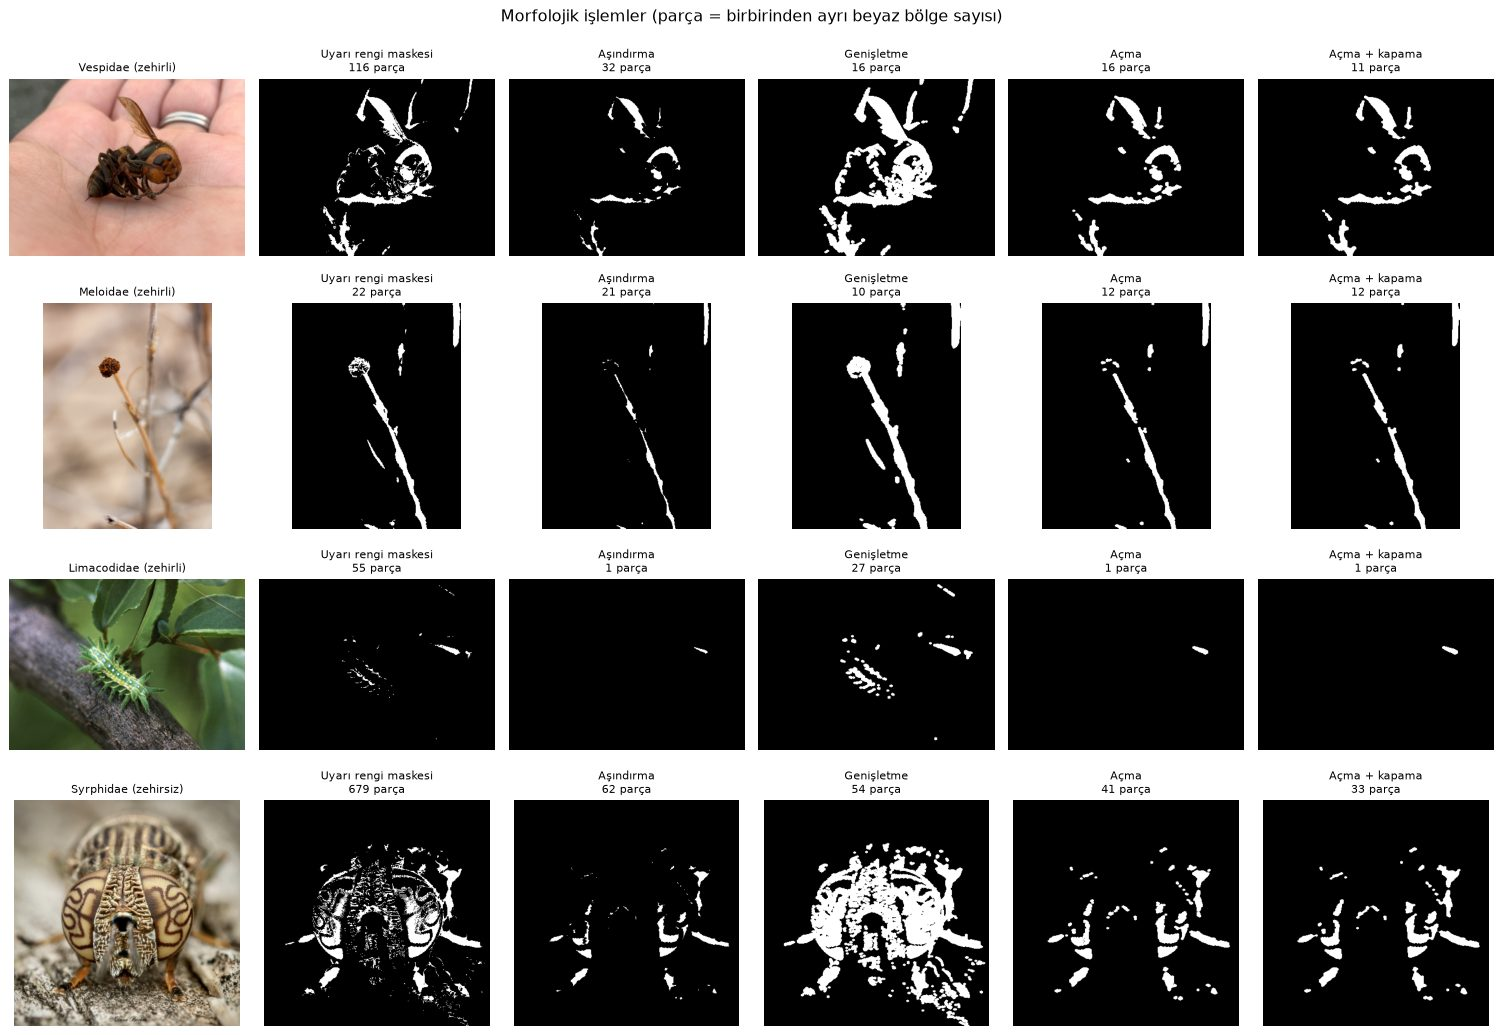

In [14]:
ye = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))

def parca_sayisi(m):
    return cv2.connectedComponents(m)[0] - 1

resimler, basliklar = [], []
for g in ["Vespidae", "Meloidae", "Limacodidae", "Syrphidae"]:
    r = foto(g, 5)
    s = renk_maskeleri(r)[1] | renk_maskeleri(r)[2]
    acma = cv2.morphologyEx(s, cv2.MORPH_OPEN, ye)
    adimlar = [("Uyarı rengi maskesi", s), ("Aşındırma", cv2.erode(s, ye)), ("Genişletme", cv2.dilate(s, ye)),
               ("Açma", acma), ("Açma + kapama", cv2.morphologyEx(acma, cv2.MORPH_CLOSE, ye))]
    resimler += [r] + [v for _, v in adimlar]
    basliklar += [etiket(g)] + [f"{k}\n{parca_sayisi(v)} parça" for k, v in adimlar]
goster(resimler, basliklar, sutun=6, boyut=2.8, baslik="Morfolojik işlemler (parça = birbirinden ayrı beyaz bölge sayısı)")

## 11. Segmentasyon: Böceğin Arka Plandan Ayrılması

Segmentasyon, görüntüdeki ilgilenilen nesnenin (burada böceğin) arka plandan ayrılması işlemidir. İki yöntem karşılaştırılmıştır:

- **Otsu eşikleme:** Gri seviye histogramını iki sınıfa en iyi ayıran eşik değerini otomatik olarak bulur. Hızlıdır, ancak arka plan karmaşık olduğunda (yaprak, çiçek, gölge) başarısı düşer.
- **GrabCut:** Görüntünün kenar bölgesini arka plan olarak kabul eder; ön plan ve arka planın renk dağılımlarını Gauss karışım modeliyle modeller ve graf kesme algoritmasıyla böceği ayırır.

Ayrılan bölgenin en büyük dış sınırı (kontur) yeşil, onu çevreleyen dikdörtgen kırmızı renkle çizilmiş ve böceğin görüntüde kapladığı alan yüzde olarak verilmiştir.

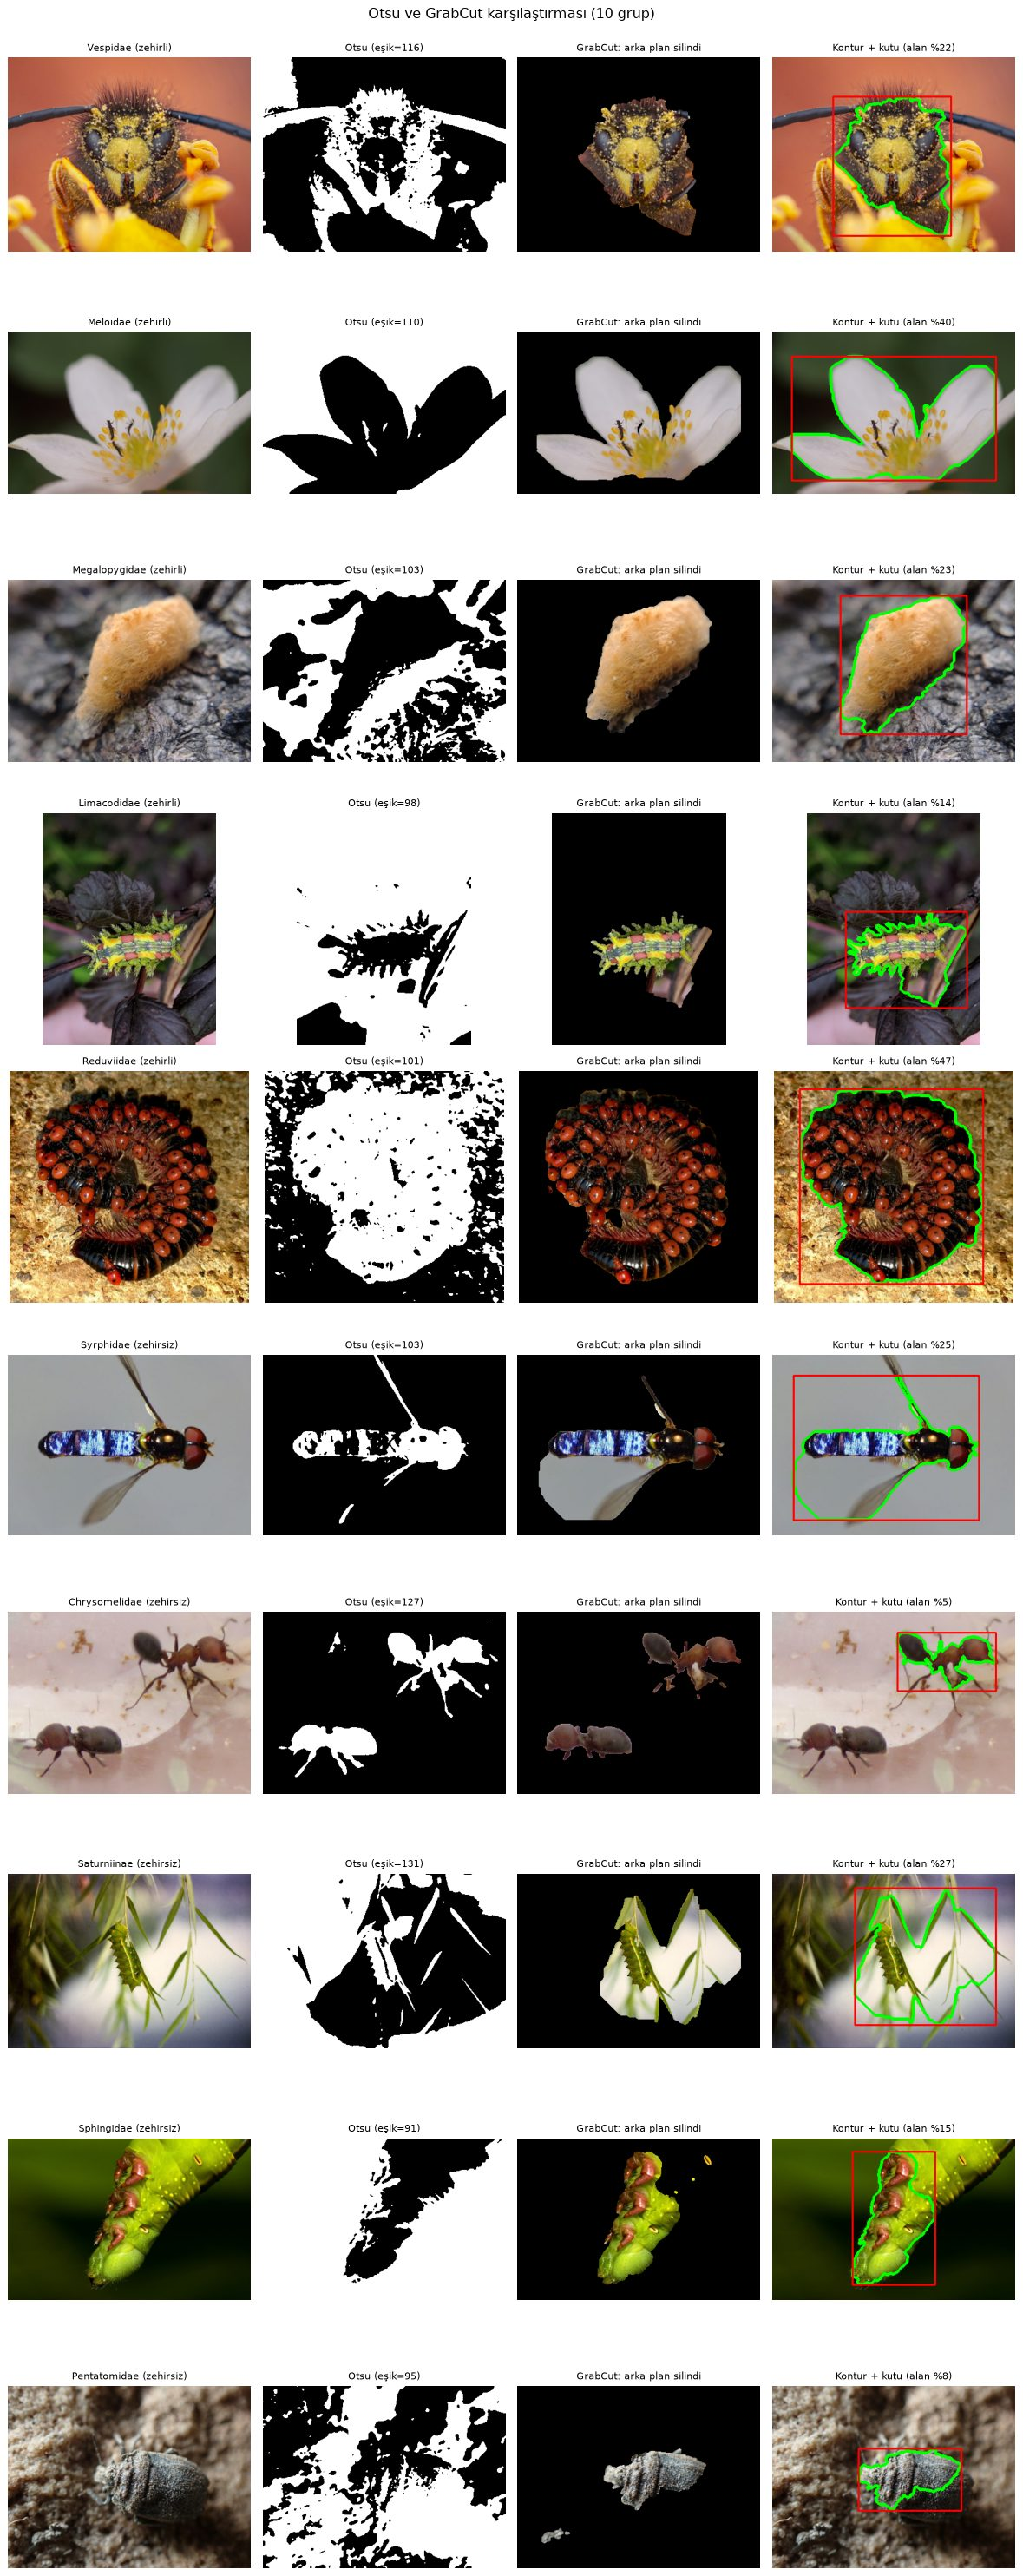

In [15]:
def grabcut(rgb, kenar=0.08, tur=5):
    h, w = rgb.shape[:2]
    m = np.zeros((h, w), np.uint8)
    dikdortgen = (int(w * kenar), int(h * kenar), int(w * (1 - 2 * kenar)), int(h * (1 - 2 * kenar)))
    cv2.grabCut(cv2.cvtColor(rgb, cv2.COLOR_RGB2BGR), m, dikdortgen, np.zeros((1, 65)), np.zeros((1, 65)),
                tur, cv2.GC_INIT_WITH_RECT)
    on_plan = np.where((m == cv2.GC_FGD) | (m == cv2.GC_PR_FGD), 255, 0).astype(np.uint8)
    return cv2.morphologyEx(on_plan, cv2.MORPH_OPEN, ye)

def kontur_ciz(rgb, maske):
    cizim = rgb.copy()
    konturlar, _ = cv2.findContours(maske, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    if not konturlar:
        return cizim, 0.0
    k = max(konturlar, key=cv2.contourArea)
    cv2.drawContours(cizim, [k], -1, (0, 255, 0), 3)
    x, y, w, h = cv2.boundingRect(k)
    cv2.rectangle(cizim, (x, y), (x + w, y + h), (255, 0, 0), 2)
    return cizim, cv2.contourArea(k) / maske.size

resimler, basliklar = [], []
for g in sira:
    r = foto(g, 6)
    gr = cv2.cvtColor(r, cv2.COLOR_RGB2GRAY)
    esik, otsu = cv2.threshold(cv2.GaussianBlur(gr, (5, 5), 0), 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
    gc = grabcut(r)
    cizim, alan = kontur_ciz(r, gc)
    resimler += [r, otsu, cv2.bitwise_and(r, r, mask=gc), cizim]
    basliklar += [etiket(g), f"Otsu (eşik={esik:.0f})", "GrabCut: arka plan silindi", f"Kontur + kutu (alan %{100 * alan:.0f})"]
goster(resimler, basliklar, sutun=4, boyut=3.3, baslik="Otsu ve GrabCut karşılaştırması (10 grup)")

## 12. Sayısal Analiz: Renk Zehirliliği Ayırt Etmeye Yeter mi?

Bu bölümde, klasik görüntü işleme ile elde edilen özelliklerin zehirli ve zehirsiz böcekleri ayırt edip edemediği incelenmiştir. 249 fotoğrafın her birinde böcek önce GrabCut ile arka plandan ayrılmış, ardından **yalnızca böceğe ait pikseller** üzerinde şu ölçümler yapılmıştır:

- Sarı/turuncu, kırmızı ve siyah piksel oranları
- **Kenar yoğunluğu:** Canny kenar piksellerinin oranı (kıl, desen ve doku ölçüsü)

Son olarak yalnızca uyarı rengi oranına dayanan basit bir karar kuralı tanımlanmıştır: *"Böcek üzerindeki uyarı rengi oranı eşik değerden büyükse zehirlidir."* Bu kuralın doğruluğu tüm eşik değerleri için hesaplanmış ve projenin derin öğrenme modeliyle (ConvNeXt-Tiny) karşılaştırılmıştır.

In [16]:
olcum = []
t0 = time.time()
for r in df.itertuples():
    m = grabcut(r.resim)
    alan = max(int((m > 0).sum()), 1)
    _, s, k, sy = renk_maskeleri(r.resim)
    c = canny(cv2.cvtColor(r.resim, cv2.COLOR_RGB2GRAY))
    olcum.append(dict(grup=r.grup, sinif=r.sinif,
                      sari=((s > 0) & (m > 0)).sum() / alan, kirmizi=((k > 0) & (m > 0)).sum() / alan,
                      siyah=((sy > 0) & (m > 0)).sum() / alan, kenar_yogunlugu=((c > 0) & (m > 0)).sum() / alan))
olcum = pd.DataFrame(olcum)
olcum["uyari_rengi"] = olcum.sari + olcum.kirmizi
print(f"{len(olcum)} fotoğraf işlendi ({time.time() - t0:.0f} sn)")

ozet = olcum.groupby(["grup", "sinif"], sort=False)[["sari", "kirmizi", "siyah", "uyari_rengi", "kenar_yogunlugu"]].mean()
(ozet * 100).round(1).rename(columns=lambda c: c + " (%)")

249 fotoğraf işlendi (234 sn)


,,sari (%),kirmizi (%),siyah (%),uyari_rengi (%),kenar_yogunlugu (%)
grup,sinif,,,,,
Vespidae,zehirli,16.8,12.5,20.0,29.3,11.8
Meloidae,zehirli,18.6,9.2,23.7,27.8,9.1
Megalopygidae,zehirli,26.7,2.1,6.3,28.8,14.6
Limacodidae,zehirli,23.0,2.8,7.0,25.8,15.6
Reduviidae,zehirli,12.8,13.1,16.7,25.8,11.5
Syrphidae,zehirsiz,19.8,3.8,19.6,23.6,12.1
Chrysomelidae,zehirsiz,17.2,10.6,14.1,27.8,12.6
Saturniinae,zehirsiz,19.4,4.4,8.8,23.8,11.0
Sphingidae,zehirsiz,32.4,7.4,10.5,39.8,10.5


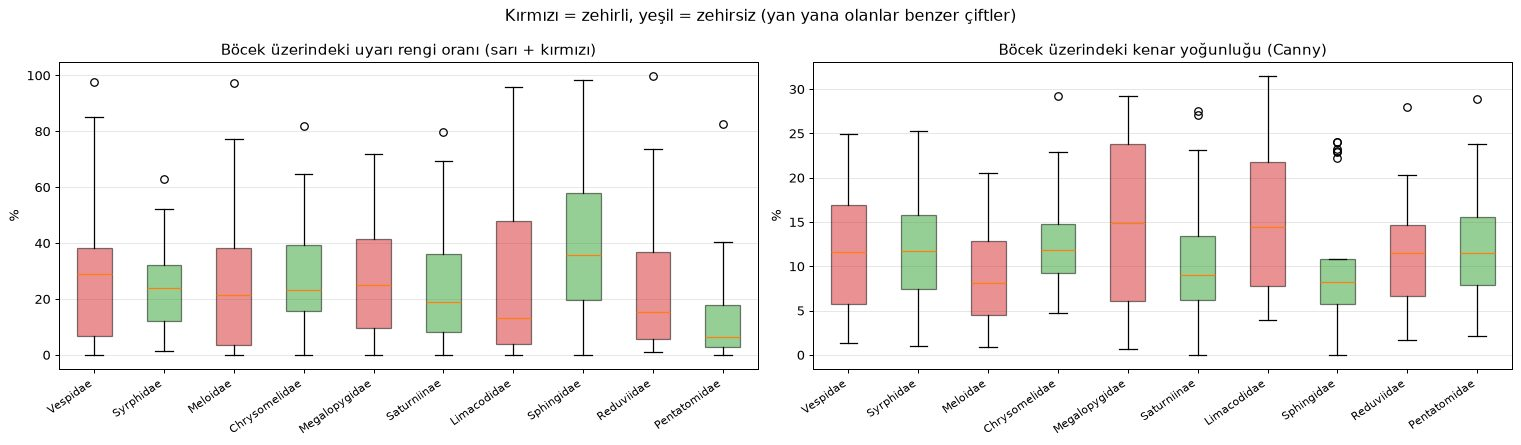

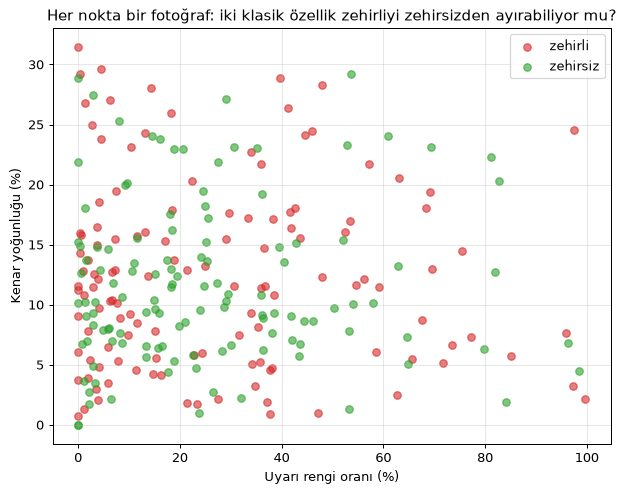

In [17]:
cift_sira = [g for z, zs, _ in CIFTLER for g in (z, zs)]
renkler = ["#d62728" if i % 2 == 0 else "#2ca02c" for i in range(len(cift_sira))]

fig, axes = plt.subplots(1, 2, figsize=(17, 5))
for ax, kol, baslik in [(axes[0], "uyari_rengi", "Böcek üzerindeki uyarı rengi oranı (sarı + kırmızı)"),
                        (axes[1], "kenar_yogunlugu", "Böcek üzerindeki kenar yoğunluğu (Canny)")]:
    kutu = ax.boxplot([olcum[olcum.grup == g][kol] * 100 for g in cift_sira], patch_artist=True)
    for p, c in zip(kutu["boxes"], renkler):
        p.set_facecolor(c); p.set_alpha(0.5)
    ax.set_xticks(range(1, len(cift_sira) + 1)); ax.set_xticklabels(cift_sira, rotation=35, ha="right", fontsize=9)
    ax.set_ylabel("%"); ax.set_title(baslik); ax.grid(alpha=0.3, axis="y")
plt.suptitle("Kırmızı = zehirli, yeşil = zehirsiz (yan yana olanlar benzer çiftler)", fontsize=13)
plt.tight_layout(); plt.show()

plt.figure(figsize=(8, 6))
for s, c in [("zehirli", "#d62728"), ("zehirsiz", "#2ca02c")]:
    d = olcum[olcum.sinif == s]
    plt.scatter(d.uyari_rengi * 100, d.kenar_yogunlugu * 100, c=c, alpha=0.6, label=s)
plt.xlabel("Uyarı rengi oranı (%)"); plt.ylabel("Kenar yoğunluğu (%)"); plt.legend(); plt.grid(alpha=0.3)
plt.title("Her nokta bir fotoğraf: iki klasik özellik zehirliyi zehirsizden ayırabiliyor mu?")
plt.show()

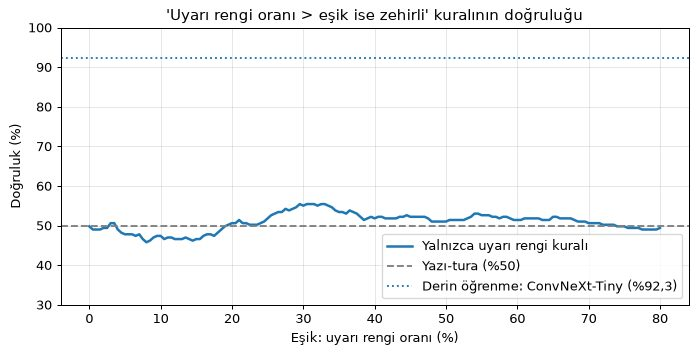

Yalnızca renge bakan kural, EN İYİ eşikte ('oran > %29.5 ise zehirli'): doğruluk %55.4
Karşılaştırma → yazı-tura: %50 | ConvNeXt-Tiny (derin öğrenme, test): %92,3


,cift,zehirli_uyari_rengi,zehirsiz_uyari_rengi,kural_dogrulugu
0,Vespidae / Syrphidae,%29.3,%23.6,%59.2
1,Meloidae / Chrysomelidae,%27.8,%27.8,%54.0
2,Megalopygidae / Saturniinae,%28.8,%23.8,%60.0
3,Limacodidae / Sphingidae,%25.8,%39.8,%40.0
4,Reduviidae / Pentatomidae,%25.8,%13.8,%64.0


In [18]:
y = (olcum.sinif == "zehirli").astype(int).values
esikler = np.linspace(0, 0.8, 161)
dogruluk = [accuracy_score(y, olcum.uyari_rengi.values > e) for e in esikler]
en_iyi = esikler[int(np.argmax(dogruluk))]

plt.figure(figsize=(9, 4))
plt.plot(esikler * 100, np.array(dogruluk) * 100, lw=2, label="Yalnızca uyarı rengi kuralı")
plt.axhline(50, color="gray", ls="--", label="Yazı-tura (%50)")
plt.axhline(92.3, color="#1f77b4", ls=":", label="Derin öğrenme: ConvNeXt-Tiny (%92,3)")
plt.xlabel("Eşik: uyarı rengi oranı (%)"); plt.ylabel("Doğruluk (%)"); plt.ylim(30, 100); plt.legend(); plt.grid(alpha=0.3)
plt.title("'Uyarı rengi oranı > eşik ise zehirli' kuralının doğruluğu"); plt.show()

print(f"Yalnızca renge bakan kural, EN İYİ eşikte ('oran > %{100 * en_iyi:.1f} ise zehirli'): doğruluk %{100 * max(dogruluk):.1f}")
print("Karşılaştırma → yazı-tura: %50 | ConvNeXt-Tiny (derin öğrenme, test): %92,3")

cift_sonuc = []
for z, zs, _ in CIFTLER:
    d = olcum[olcum.grup.isin([z, zs])]
    cift_sonuc.append(dict(cift=f"{z} / {zs}",
                           zehirli_uyari_rengi=f"%{100 * d[d.grup == z].uyari_rengi.mean():.1f}",
                           zehirsiz_uyari_rengi=f"%{100 * d[d.grup == zs].uyari_rengi.mean():.1f}",
                           kural_dogrulugu=f"%{100 * accuracy_score(d.sinif == 'zehirli', d.uyari_rengi > en_iyi):.1f}"))
pd.DataFrame(cift_sonuc)

## 13. Sonuç

- **Kontrast iyileştirme:** Histogram eşitleme ve CLAHE, karanlık fotoğraflardaki ayrıntıları görünür hale getirmiştir. CLAHE'nin LAB uzayında yalnızca parlaklık kanalına uygulanması, renkleri bozmadan iyileştirme sağlamıştır.
- **Gürültü giderme:** Uygun filtre gürültü türüne bağlıdır. Tuz-biber gürültüsünde **3×3 medyan filtre** açık farkla en iyi sonucu vermiştir (17,5 dB → 41,3 dB). Gauss gürültüsünde ortalama, Gauss, 5×5 medyan ve bilateral filtreler birbirine yakın sonuç vermiş (yaklaşık 31–32 dB); bilateral filtre ise tuz-biber gürültüsünü hiç giderememiştir.
- **Evrişim ve kenar bulma:** Aynı görüntü, yalnızca 3×3 çekirdeğin değerleri değiştirilerek bulanıklaştırılmış, keskinleştirilmiş veya kenarlarına ayrılmıştır. Elle tanımlanan Sobel çekirdeği `cv2.Sobel` ile birebir aynı sonucu vermiştir. Canny yöntemi en ince ve sürekli kenarları üretmiştir.
- **Segmentasyon:** Otsu eşikleme karmaşık arka planlarda başarısız olmuştur. GrabCut böceği çoğu fotoğrafta başarıyla ayırmış, ancak böceğin küçük olduğu ya da arka planın (çiçek, yaprak) dikkat çekici olduğu durumlarda hatalı sonuç vermiştir.
- **Renk analizi:** HSV maskesi uyarı renklerini başarıyla yakalamıştır. Ancak renk maskesi nesneyi tanımadığından arka plandaki renkleri de seçmektedir. Böcek arka plandan ayrıldıktan sonra yapılan ölçümlerde zehirsiz grupların da benzer oranda uyarı rengi taşıdığı görülmüştür (ör. Sphingidae tırtılları %39,8 ile en yüksek orana sahiptir). Yalnızca renge dayanan karar kuralı en iyi eşikte bile **%55,4** doğruluğa ulaşabilmiştir; bu değer yazı-tura düzeyine (%50) yakındır.

Bu bulgular, zehirli ve zehirsiz böceklerin tek bir görsel özellikle ayırt edilemeyeceğini göstermektedir. Bu nedenle projenin sınıflandırma aşamasında renk, kenar, doku ve şekil bilgisini birlikte ve otomatik olarak öğrenen **evrişimli sinir ağları** kullanılmış; ConvNeXt-Tiny modeli test verisinde **%92,3** doğruluğa ulaşmıştır.